# 04. Analysis & figures
Dataset statistics, model diagrams, SHAP, t-SNE/UMAP, t-tests, odds ratios and hyperparameter ablation.

## Dataset distribution


📌 데이터셋 개수 및 비율:
  - Train 개수: 71002 (85.71%)
  - Validation 개수: 7099 (8.57%)
  - Test 개수: 4742 (5.72%)
  - 전체 데이터 개수: 82843 (Train:Val:Test = 85.7:8.6:5.7)

📌 감정별 데이터 개수 및 비율:
  - Happy: Train=11251 (15.85%), Validation=1123 (15.82%), Test=753 (15.88%)
  - Sad: Train=10058 (14.17%), Validation=1003 (14.13%), Test=669 (14.11%)
  - Anger: Train=9863 (13.89%), Validation=986 (13.89%), Test=659 (13.90%)
  - Surprise: Train=8858 (12.48%), Validation=887 (12.49%), Test=592 (12.48%)
  - Disgust: Train=10485 (14.77%), Validation=1049 (14.78%), Test=702 (14.80%)
  - Neutral: Train=11051 (15.56%), Validation=1106 (15.58%), Test=739 (15.58%)
  - Fear: Train=9436 (13.29%), Validation=945 (13.31%), Test=628 (13.24%)


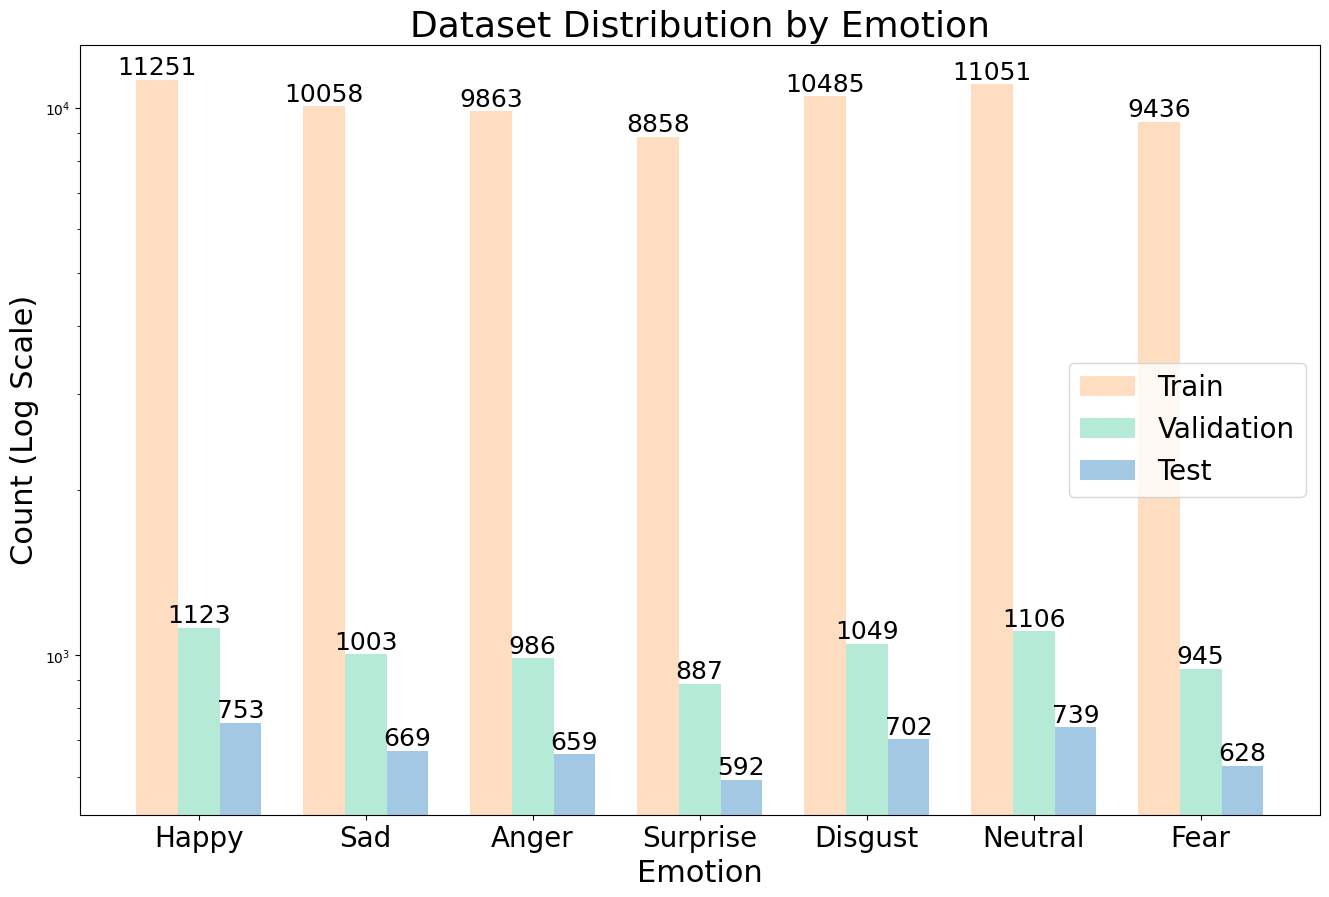

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 감정 레이블 정의
emotion_labels = {
    0: "Happy",
    1: "Sad",
    2: "Anger",
    3: "Surprise",
    4: "Disgust",
    5: "Neutral",
    6: "Fear",
}

# TFRecord 파싱 함수
def parse_tfrecord_count(tfrecord):
    features = {
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)
    return parsed_features["label"]

# 데이터셋 로드 및 라벨 카운트
def count_labels_in_tfrecord(tfrecord_file):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_tfrecord_count)

    label_counts = np.zeros(len(emotion_labels), dtype=int)
    for label in dataset.as_numpy_iterator():
        label_counts[label] += 1

    return label_counts

# TFRecord 파일 경로
train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

# 감정별 데이터 개수 카운트
train_counts = count_labels_in_tfrecord(train_tfrecord_file)
val_counts = count_labels_in_tfrecord(val_tfrecord_file)
test_counts = count_labels_in_tfrecord(test_tfrecord_file)

# 전체 데이터 개수
total_train = np.sum(train_counts)
total_val = np.sum(val_counts)
total_test = np.sum(test_counts)
total_all = total_train + total_val + total_test

# 데이터 비율 계산
train_ratio = total_train / total_all * 100
val_ratio = total_val / total_all * 100
test_ratio = total_test / total_all * 100

# 감정별 비율 계산
train_percentage = (train_counts / total_train) * 100
val_percentage = (val_counts / total_val) * 100
test_percentage = (test_counts / total_test) * 100

# 📌 데이터 요약 출력
print("\n📌 데이터셋 개수 및 비율:")
print(f"  - Train 개수: {total_train} ({train_ratio:.2f}%)")
print(f"  - Validation 개수: {total_val} ({val_ratio:.2f}%)")
print(f"  - Test 개수: {total_test} ({test_ratio:.2f}%)")
print(f"  - 전체 데이터 개수: {total_all} (Train:Val:Test = {train_ratio:.1f}:{val_ratio:.1f}:{test_ratio:.1f})\n")

# 감정별 데이터 개수 출력
print("📌 감정별 데이터 개수 및 비율:")
for i, emotion in emotion_labels.items():
    print(f"  - {emotion}: Train={train_counts[i]} ({train_percentage[i]:.2f}%), "
          f"Validation={val_counts[i]} ({val_percentage[i]:.2f}%), "
          f"Test={test_counts[i]} ({test_percentage[i]:.2f}%)")

# 📊 데이터 시각화
fig, ax = plt.subplots(figsize=(16, 10))  # 그래프 크기 키움
bar_width = 0.25
index = np.arange(len(emotion_labels))

# 바 차트 그리기 (연한 파스텔톤 색상 적용)
bars1 = ax.bar(index, train_counts, bar_width, label="Train", color='#FFDDC1')  # 연한 오렌지
bars2 = ax.bar(index + bar_width, val_counts, bar_width, label="Validation", color='#B5EAD7')  # 연한 민트
bars3 = ax.bar(index + 2 * bar_width, test_counts, bar_width, label="Test", color='#A2C8E3')  # 연한 블루

# 각 막대 위에 숫자 표시 (크기 키움)
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', fontsize=18)

# y축 로그 스케일 적용 (2000~8000 구간 생략)
ax.set_yscale("log")

# 축 설정 및 스타일 적용
ax.set_xlabel("Emotion", fontsize=22)
ax.set_ylabel("Count (Log Scale)", fontsize=22)
ax.set_title("Dataset Distribution by Emotion", fontsize=26)
ax.set_xticks(index + bar_width)
ax.set_xticklabels(emotion_labels.values(), fontsize=20)
ax.legend(fontsize=20)
# ax.yaxis.grid(True, linestyle="--", alpha=0.7)

# 그래프 표시
plt.show()


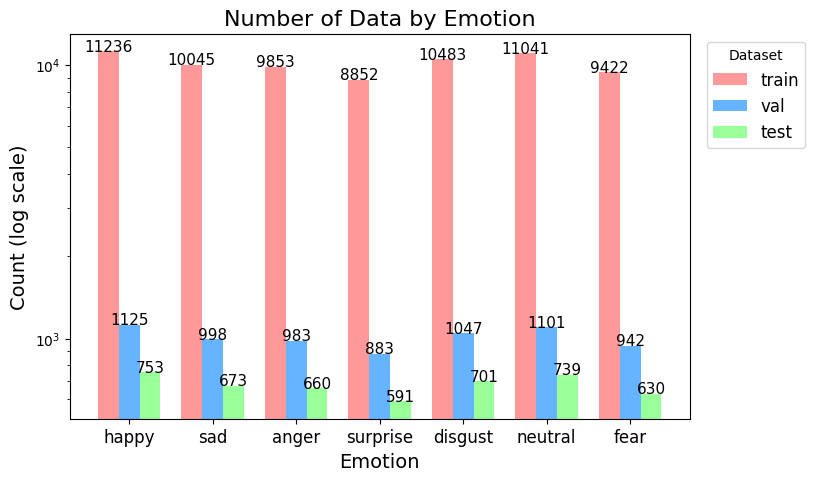

In [ ]:
import matplotlib.pyplot as plt

# 색상 조정 (파스텔톤)
train_color = "#ff9999"  # 연한 빨강
val_color = "#66b3ff"  # 연한 파랑
test_color = "#99ff99"  # 연한 초록

# 그래프 크기 설정
plt.figure(figsize=(8, 5))

# 로그 스케일을 적용하여 그래프 그리기
plt.bar(x_indexes, train_counts, width=bar_width, color=train_color, label="train")
plt.bar(x_indexes + bar_width, val_counts, width=bar_width, color=val_color, label="val")
plt.bar(x_indexes + 2 * bar_width, test_counts, width=bar_width, color=test_color, label="test")

# 로그 스케일 적용
plt.yscale("log")

# 데이터 값 추가 (숫자가 겹치지 않도록 위치 조정)
for i, (train, val, test) in enumerate(zip(train_counts, val_counts, test_counts)):
    plt.text(x_indexes[i], train , str(train), ha="center", fontsize=11)  # train 값 위로 이동
    plt.text(x_indexes[i] + bar_width, val , str(val), ha="center", fontsize=11)  # val 값 위로 이동
    plt.text(x_indexes[i] + 2 * bar_width, test , str(test), ha="center", fontsize=11)  # test 값 위로 이동

# x축, y축, 제목 설정
plt.xticks(ticks=x_indexes + bar_width, labels=emotions, fontsize=12)
plt.xlabel("Emotion", fontsize=14)
plt.ylabel("Count (log scale)", fontsize=14)
plt.title("Number of Data by Emotion", fontsize=16)

# 범례 위치 조정 (그래프와 겹치지 않도록 오른쪽 상단으로 이동)
plt.legend(title="Dataset", fontsize=12, loc="upper right", bbox_to_anchor=(1.2, 1))

# 그래프 출력
plt.show()


## Model architecture diagrams

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-6ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 29 not upgraded.


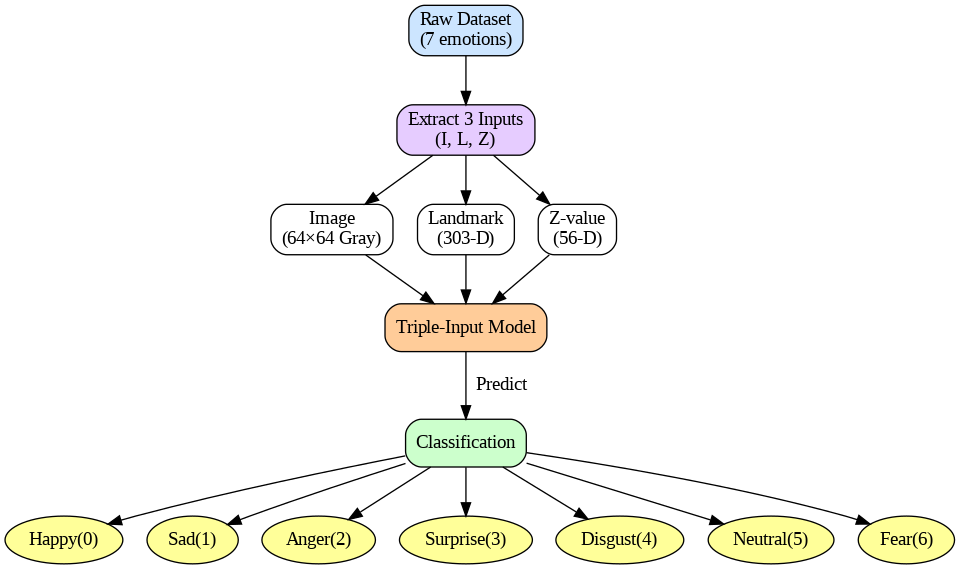

In [ ]:
# --- (1) Colab 환경에서 Graphviz 설치
!apt-get install -y graphviz
!pip install graphviz

# --- (2) Graphviz 코드 작성 & 렌더링
from graphviz import Digraph
from IPython.display import display
from PIL import Image
import io

dot = Digraph(comment='Triple-Input Flow')
dot.attr(rankdir='TB', size='10,10')  # TB: 위->아래, LR: 좌->우

# 노드 정의 (각각의 흐름 단계)
dot.node('A', 'Raw Dataset\n(7 emotions)', shape='box', style='rounded,filled', fillcolor='#CCE5FF')
dot.node('B', 'Extract 3 Inputs\n(I, L, Z)', shape='box', style='rounded,filled', fillcolor='#E6CCFF')
dot.node('C1', 'Image\n(64×64 Gray)', shape='box', style='rounded', fillcolor='#FFFFFF')
dot.node('C2', 'Landmark\n(303-D)', shape='box', style='rounded', fillcolor='#FFFFFF')
dot.node('C3', 'Z-value\n(56-D)', shape='box', style='rounded', fillcolor='#FFFFFF')
dot.node('D', 'Triple-Input Model', shape='box', style='rounded,filled', fillcolor='#FFCC99')
dot.node('E', 'Classification', shape='box', style='rounded,filled', fillcolor='#CCFFCC')

# 감정별 분류 노드 추가 (레이블 포함)
emotions = ['Happy(0)', 'Sad(1)', 'Anger(2)', 'Surprise(3)', 'Disgust(4)', 'Neutral(5)', 'Fear(6)']
for i, emotion in enumerate(emotions):
    dot.node(f'F{i}', emotion, shape='ellipse', style='filled', fillcolor='#FFFF99')

# 엣지(연결) 정의
dot.edge('A', 'B')
dot.edge('B', 'C1')
dot.edge('B', 'C2')
dot.edge('B', 'C3')
dot.edge('C1', 'D')
dot.edge('C2', 'D')
dot.edge('C3', 'D')
dot.edge('D', 'E', label='  Predict', labeldistance="2.5")  # 글자 화살표 중앙 배치

# 7가지 감정으로 화살표 연결
for i in range(len(emotions)):
    dot.edge('E', f'F{i}')

# --- (3) Colab에서 바로 이미지 출력
img_bytes = dot.pipe(format='png')  # PNG로 변환
img = Image.open(io.BytesIO(img_bytes))  # 이미지 열기
display(img)  # 출력


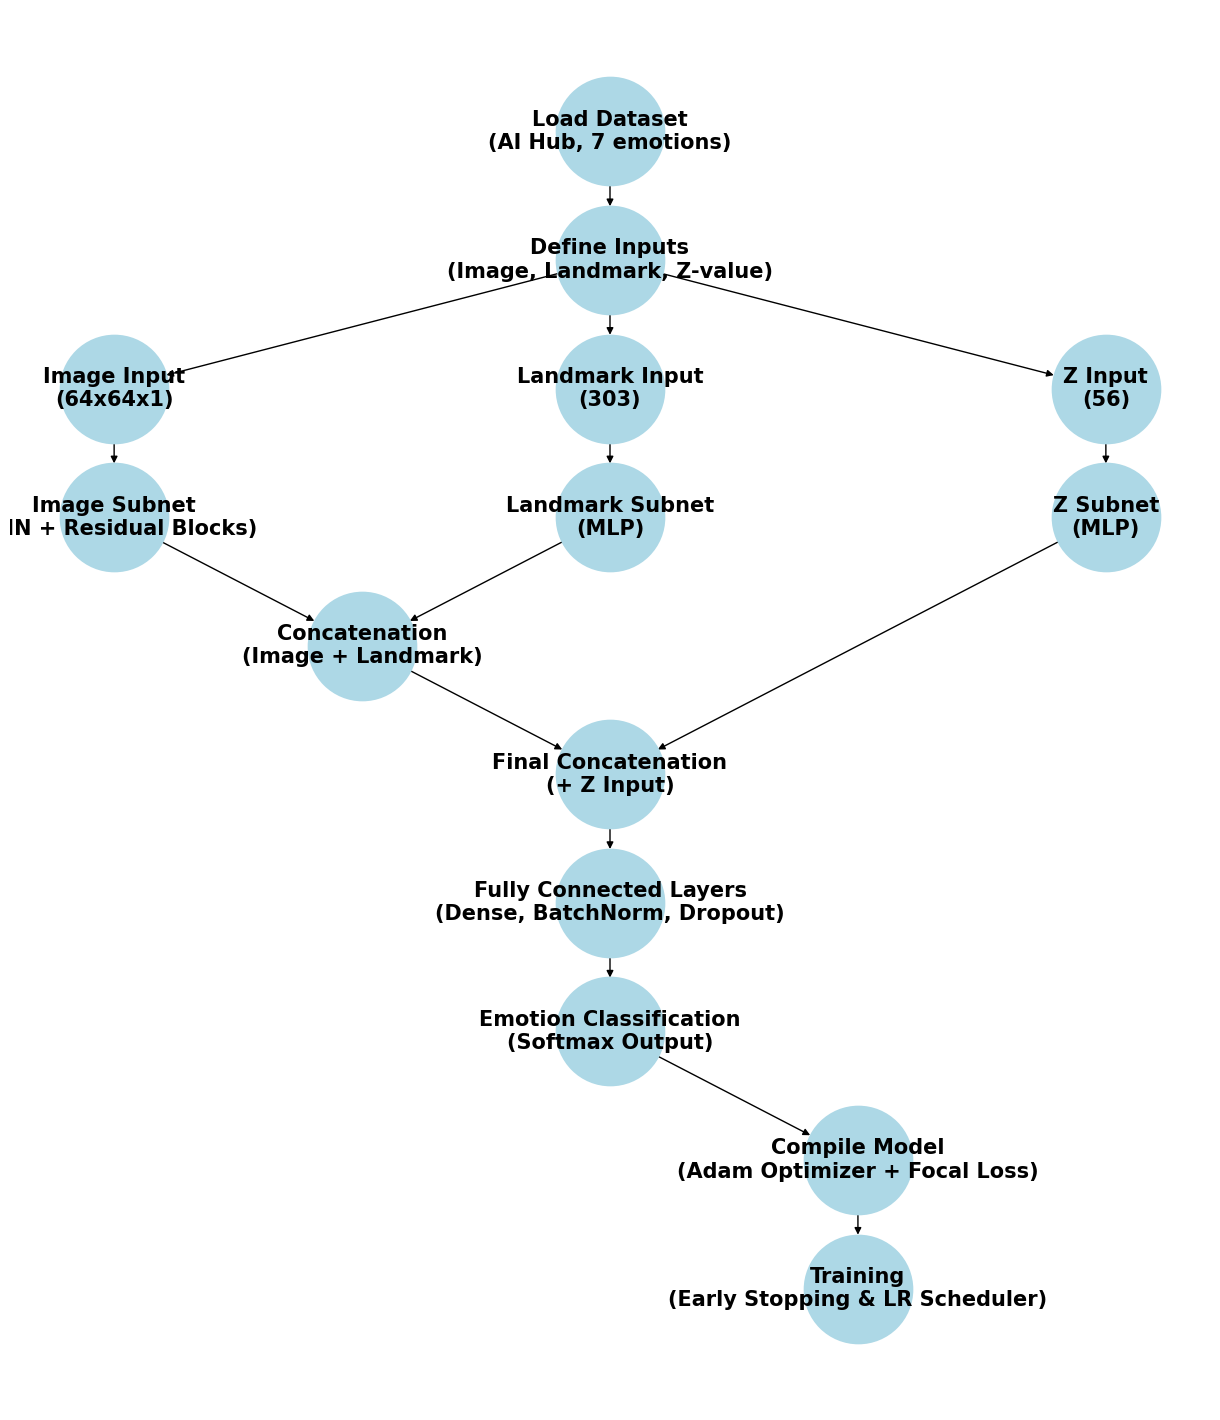

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

def draw_model_diagram():
    G = nx.DiGraph()

    # 노드 정의 (11가지 단계 + 추가적인 세부 요소)
    nodes = {
        "Load Dataset": "Load Dataset\n(AI Hub, 7 emotions)",
        "Define Inputs": "Define Inputs\n(Image, Landmark, Z-value)",
        "Image Input": "Image Input\n(64x64x1)",
        "Landmark Input": "Landmark Input\n(303)",
        "Z Input": "Z Input\n(56)",
        "Image Subnet": "Image Subnet\n(CNN + Residual Blocks)",
        "Landmark Subnet": "Landmark Subnet\n(MLP)",
        "Z Subnet": "Z Subnet\n(MLP)",
        "Concat Img & Landmark": "Concatenation\n(Image + Landmark)",
        "Final Concat": "Final Concatenation\n(+ Z Input)",
        "FC Layers": "Fully Connected Layers\n(Dense, BatchNorm, Dropout)",
        "Emotion Classification": "Emotion Classification\n(Softmax Output)",
        "Compile Model": "Compile Model\n(Adam Optimizer + Focal Loss)",
        "Training": "Training\n(Early Stopping & LR Scheduler)"
    }

    for key, label in nodes.items():
        G.add_node(key, label=label, shape='box')

    # 엣지(연결) 정의
    edges = [
        ("Load Dataset", "Define Inputs"),
        ("Define Inputs", "Image Input"),
        ("Define Inputs", "Landmark Input"),
        ("Define Inputs", "Z Input"),
        ("Image Input", "Image Subnet"),
        ("Landmark Input", "Landmark Subnet"),
        ("Z Input", "Z Subnet"),
        ("Image Subnet", "Concat Img & Landmark"),
        ("Landmark Subnet", "Concat Img & Landmark"),
        ("Concat Img & Landmark", "Final Concat"),
        ("Z Subnet", "Final Concat"),
        ("Final Concat", "FC Layers"),
        ("FC Layers", "Emotion Classification"),
        ("Emotion Classification", "Compile Model"),
        ("Compile Model", "Training")
    ]

    G.add_edges_from(edges)

    # 레이아웃 배치 (위->아래 흐름)
    pos = {
        "Load Dataset": (2, 7),
        "Define Inputs": (2, 6),
        "Image Input": (0, 5), "Landmark Input": (2, 5), "Z Input": (4, 5),
        "Image Subnet": (0, 4), "Landmark Subnet": (2, 4), "Z Subnet": (4, 4),
        "Concat Img & Landmark": (1, 3), "Final Concat": (2, 2),
        "FC Layers": (2, 1), "Emotion Classification": (2, 0),
        "Compile Model": (3, -1), "Training": (3, -2)
    }

    plt.figure(figsize=(12, 14))
    nx.draw(G, pos, with_labels=True, node_size=6000, node_color='lightblue', edge_color='black', linewidths=1.5, font_size=15, font_weight='bold', labels=nodes)
    plt.show()

draw_model_diagram()


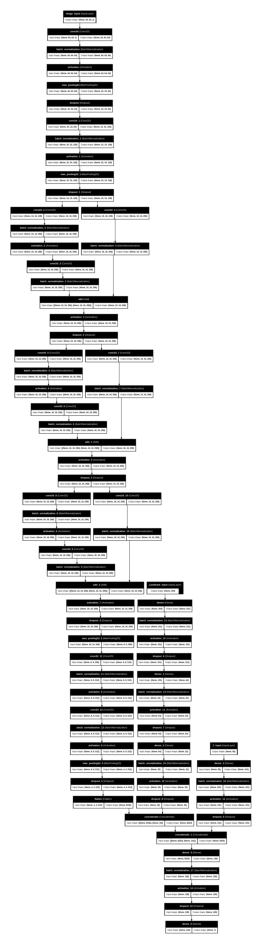

In [ ]:
# Colab 환경에서 필요한 라이브러리 설치
!pip install pydot graphviz

import tensorflow as tf
from tensorflow.keras.utils import plot_model
import matplotlib.pyplot as plt
import networkx as nx

# 모델 정의 (위 코드 그대로 사용)
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Conv2D, BatchNormalization, Activation, MaxPooling2D, Dropout, Flatten, Add, Concatenate
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 입력 정의
model_image_input = Input(shape=(64, 64, 1), name="Image_Input")
model_landmark_input = Input(shape=(303,), name="Landmark_Input")
model_z_input = Input(shape=(56,), name="Z_Input")

# 이미지 서브넷 (CNN + Residual Blocks)
x_image = Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal')(model_image_input)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

x_image = Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

# Residual Blocks
for _ in range(3):
    shortcut = x_image
    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)

    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)

    shortcut = Conv2D(256, (1,1), padding='same', kernel_initializer='he_normal')(shortcut)
    shortcut = BatchNormalization()(shortcut)

    x_image = Add()([x_image, shortcut])
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)

x_image = MaxPooling2D((2,2))(x_image)

# 마지막 CNN 레이어
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.5)(x_image)

x_image = Flatten()(x_image)

# 랜드마크 서브넷 (MLP)
x_landmark = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_landmark_input)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(64, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(32, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

# 이미지 & 랜드마크 결합
combined_image_landmark = Concatenate()([x_image, x_landmark])

# z-값 서브넷 (MLP)
x_z = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_z_input)
x_z = BatchNormalization()(x_z)
x_z = Activation('elu')(x_z)
x_z = Dropout(0.2)(x_z)

# 최종 결합
combined = Concatenate()([combined_image_landmark, x_z])
combined = Dense(128, kernel_regularizer=l2(0.005), kernel_initializer='he_normal')(combined)
combined = BatchNormalization()(combined)
combined = Activation('elu')(combined)
combined = Dropout(0.5)(combined)

# 출력 레이어
emotion_labels = 7
model_output = Dense(emotion_labels, activation='softmax', kernel_regularizer=l2(0.005))(combined)

# 모델 정의
model_combined = Model(inputs=[model_image_input, model_landmark_input, model_z_input], outputs=model_output)

# 모델 구조 시각화
plot_model(model_combined, to_file='model_architecture.png', show_shapes=True, show_layer_names=True, dpi=150)

# 모델 구조 그래프 출력
img = plt.imread('model_architecture.png')
plt.figure(figsize=(12, 12))
plt.imshow(img)
plt.axis('off')
plt.show()


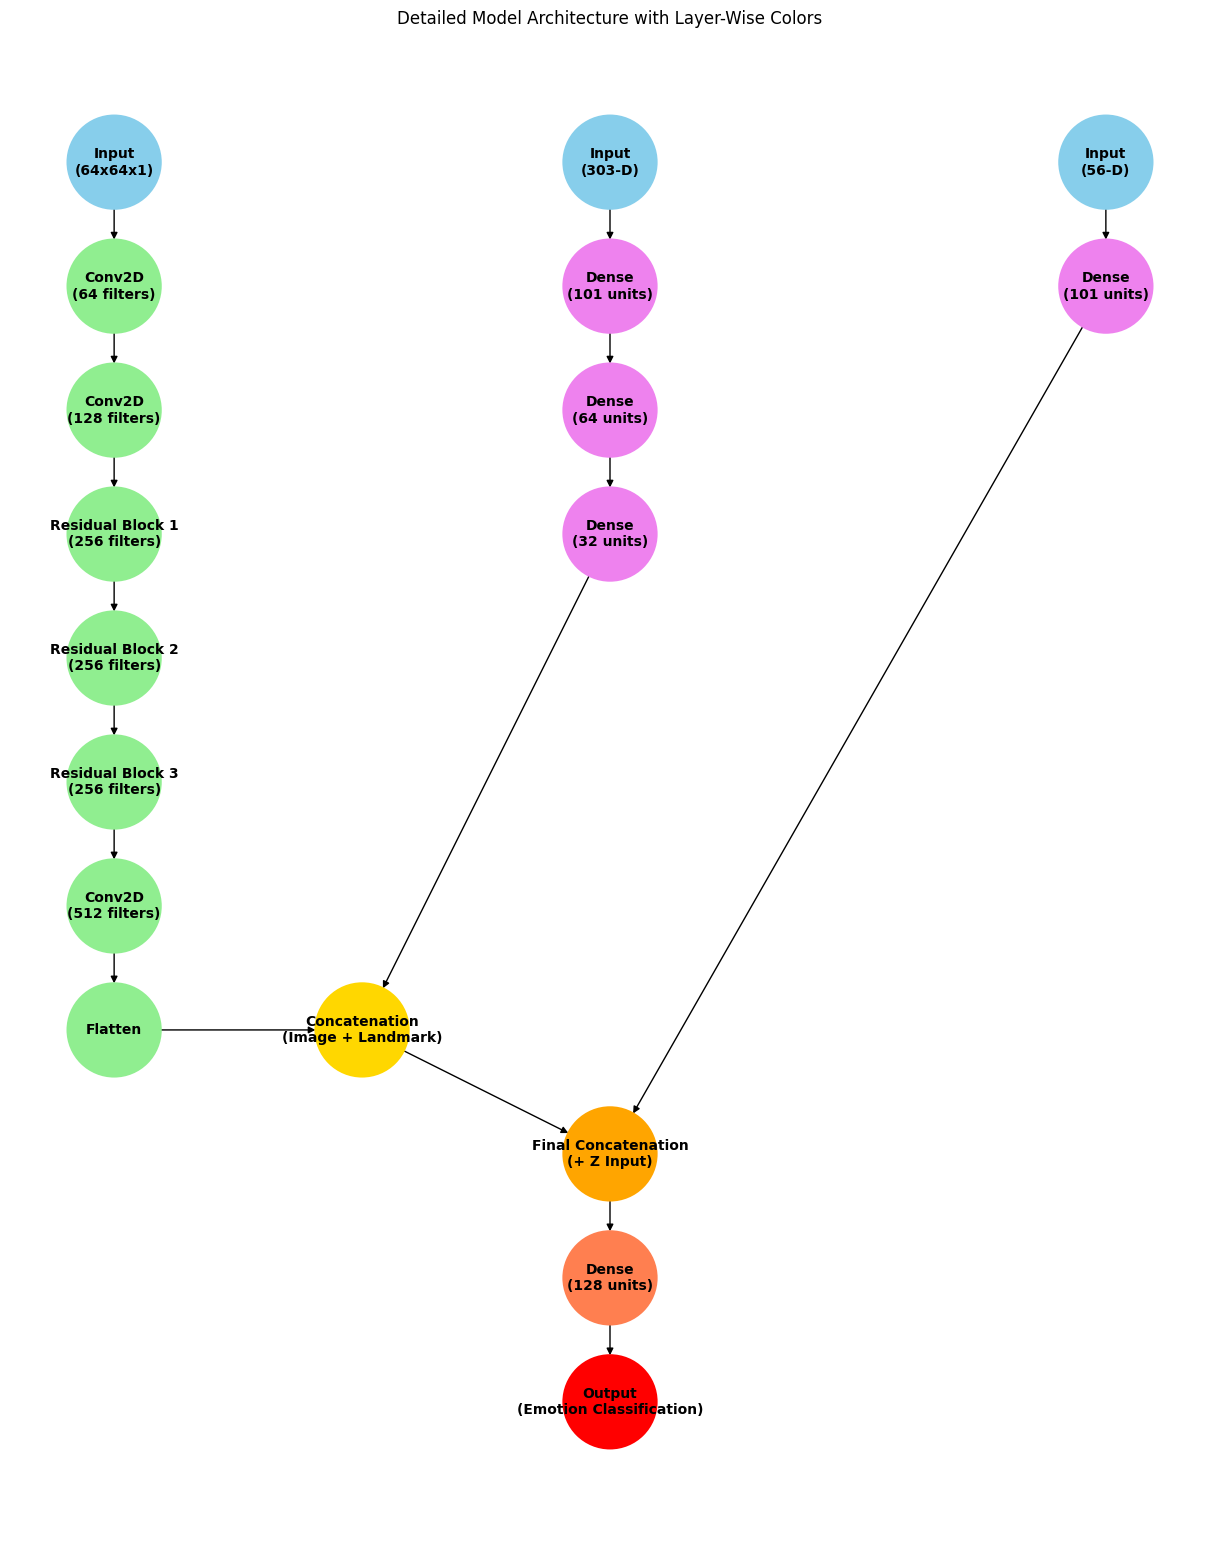

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

def draw_detailed_model_diagram():
    G = nx.DiGraph()

    # 노드 (레이어별 색상 지정)
    nodes = {
        # 입력
        "Image Input": ("Input\n(64x64x1)", "skyblue"),
        "Landmark Input": ("Input\n(303-D)", "skyblue"),
        "Z Input": ("Input\n(56-D)", "skyblue"),

        # 이미지 서브넷 (CNN + Residual Blocks)
        "Conv2D-64": ("Conv2D\n(64 filters)", "lightgreen"),
        "Conv2D-128": ("Conv2D\n(128 filters)", "lightgreen"),
        "Residual Block 1": ("Residual Block 1\n(256 filters)", "lightgreen"),
        "Residual Block 2": ("Residual Block 2\n(256 filters)", "lightgreen"),
        "Residual Block 3": ("Residual Block 3\n(256 filters)", "lightgreen"),
        "Conv2D-512": ("Conv2D\n(512 filters)", "lightgreen"),
        "Flatten": ("Flatten", "lightgreen"),

        # 랜드마크 서브넷 (MLP)
        "Dense-101": ("Dense\n(101 units)", "violet"),
        "Dense-64": ("Dense\n(64 units)", "violet"),
        "Dense-32": ("Dense\n(32 units)", "violet"),

        # Z 서브넷 (MLP)
        "Dense-Z-101": ("Dense\n(101 units)", "violet"),

        # 특성 결합
        "Concat Img & Landmark": ("Concatenation\n(Image + Landmark)", "gold"),
        "Final Concat": ("Final Concatenation\n(+ Z Input)", "orange"),

        # Fully Connected Layers
        "FC-128": ("Dense\n(128 units)", "coral"),
        "Output": ("Output\n(Emotion Classification)", "red"),
    }

    # 그래프에 노드 추가
    for key, (label, color) in nodes.items():
        G.add_node(key, label=label, color=color)

    # 엣지(연결) 정의
    edges = [
        ("Image Input", "Conv2D-64"),
        ("Conv2D-64", "Conv2D-128"),
        ("Conv2D-128", "Residual Block 1"),
        ("Residual Block 1", "Residual Block 2"),
        ("Residual Block 2", "Residual Block 3"),
        ("Residual Block 3", "Conv2D-512"),
        ("Conv2D-512", "Flatten"),

        ("Landmark Input", "Dense-101"),
        ("Dense-101", "Dense-64"),
        ("Dense-64", "Dense-32"),

        ("Z Input", "Dense-Z-101"),

        ("Flatten", "Concat Img & Landmark"),
        ("Dense-32", "Concat Img & Landmark"),
        ("Concat Img & Landmark", "Final Concat"),
        ("Dense-Z-101", "Final Concat"),

        ("Final Concat", "FC-128"),
        ("FC-128", "Output"),
    ]

    G.add_edges_from(edges)

    # 노드 위치 (위->아래 흐름)
    pos = {
        "Image Input": (0, 9), "Landmark Input": (2, 9), "Z Input": (4, 9),

        "Conv2D-64": (0, 8), "Conv2D-128": (0, 7),
        "Residual Block 1": (0, 6), "Residual Block 2": (0, 5),
        "Residual Block 3": (0, 4), "Conv2D-512": (0, 3), "Flatten": (0, 2),

        "Dense-101": (2, 8), "Dense-64": (2, 7), "Dense-32": (2, 6),
        "Dense-Z-101": (4, 8),

        "Concat Img & Landmark": (1, 2),
        "Final Concat": (2, 1),

        "FC-128": (2, 0), "Output": (2, -1),
    }

    # 그래프 스타일 설정
    plt.figure(figsize=(12, 15))
    node_colors = [nodes[node][1] for node in G.nodes()]
    nx.draw(
        G, pos, with_labels=True, node_size=4500, node_color=node_colors,
        edge_color='black', linewidths=1.5, font_size=10, font_weight='bold',
        labels={node: nodes[node][0] for node in nodes}
    )

    plt.title("Detailed Model Architecture with Layer-Wise Colors")
    plt.show()

draw_detailed_model_diagram()


## SHAP


🔹 Shape After Processing:
Images: (1000, 64, 64, 1), Landmarks: (1000, 303), Z-values: (1000, 56)
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

🔹 Applying t-SNE for Image Features: (1000, 8192)


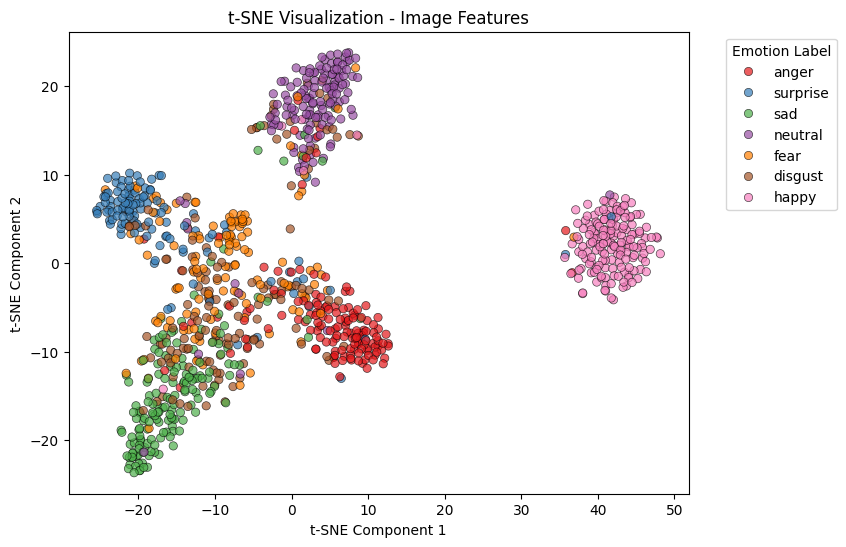


🔹 Applying t-SNE for Landmark Features: (1000, 32)


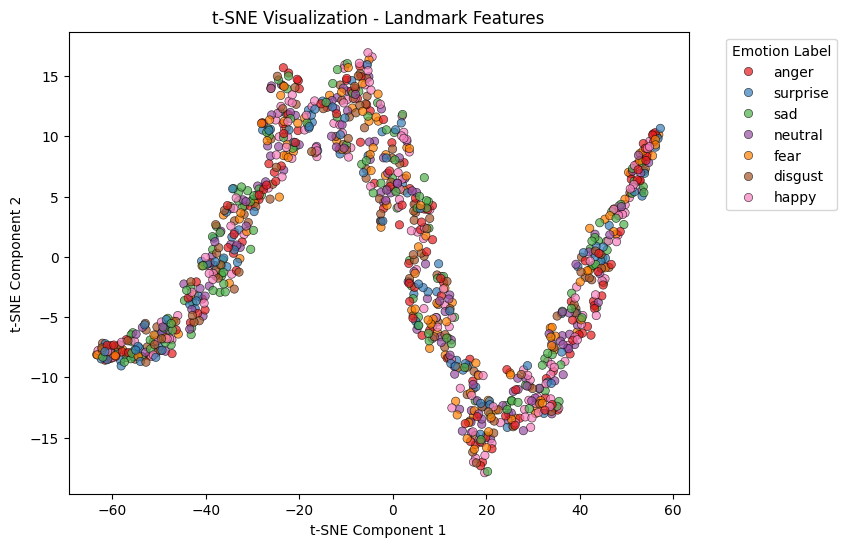


🔹 Applying t-SNE for Z-value Features: (1000, 101)


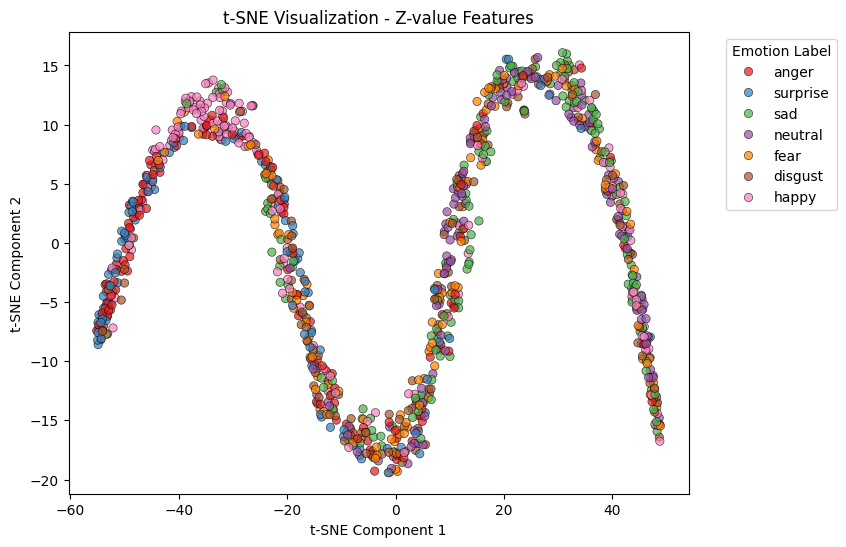

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns


# 🔹 테스트 데이터 가져오기
num_samples = 1000
test_dataset = load_test_dataset(test_tfrecord_file).shuffle(buffer_size=4747)
sample = next(iter(test_dataset.take(num_samples).batch(num_samples)))

# 🔹 개별 입력 데이터 추출
images, landmarks, z_values = sample[0]  # (image, landmarks, z_values)
labels = np.argmax(sample[1], axis=1)  # One-hot -> 정수형 라벨 변환

# ✅ **입력 데이터 타입 변환 (Tensor → NumPy)**
landmarks = np.array(landmarks, dtype=np.float32)
z_values = np.array(z_values, dtype=np.float32)

print(f"\n🔹 Shape After Processing:")
print(f"Images: {images.shape}, Landmarks: {landmarks.shape}, Z-values: {z_values.shape}")

### **1️⃣ 이미지 특징 벡터 추출 (CNN Feature)**
feature_extractor_img = tf.keras.Model(
    inputs=model.input[0],  # 이미지 입력
    outputs=model.get_layer("flatten").output  # CNN Feature Layer
)
features_img = feature_extractor_img.predict(images)

### **2️⃣ 랜드마크 특징 벡터 추출 (올바른 Dense Feature)**
feature_extractor_lmk = tf.keras.Model(
    inputs=model.input[1],  # 랜드마크 입력
    outputs=model.get_layer("dense_2").output  # 🔥 랜드마크 관련 Dense 레이어 선택
)
features_lmk = feature_extractor_lmk.predict(landmarks)

### **3️⃣ Z-value 특징 벡터 추출 (Dense Feature)**
feature_extractor_z = tf.keras.Model(
    inputs=model.input[2],  # Z-value 입력
    outputs=model.get_layer("dense_3").output  # 🔥 Z-value 관련 Dense 레이어 선택
)
features_z = feature_extractor_z.predict(z_values)

import numpy as np
import tensorflow as tf
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# ✅ 감정 라벨 매핑 (숫자 → 감정 이름)
emotion_labels = {
    0: "happy", 1: "sad", 2: "anger", 3: "surprise",
    4: "disgust", 5: "neutral", 6: "fear"
}
label_names = [emotion_labels[label] for label in labels]  # 숫자 → 문자열 변환

# ✅ 노란색 제외한 사용자 정의 색상 팔레트 (Set1에서 #FFD700 제거)
custom_palette = [
    "#e41a1c",  # Red (anger)
    "#377eb8",  # Blue (sad)
    "#4daf4a",  # Green (happy)
    "#984ea3",  # Purple (surprise)
    "#ff7f00",  # Orange (disgust)
    "#a65628",  # Brown (neutral)
    "#f781bf"   # Pink (fear)
]

# ✅ **t-SNE 변환 함수**
def apply_tsne(features, labels, title):
    print(f"\n🔹 Applying t-SNE for {title}: {features.shape}")

    if len(features.shape) > 2:  # 차원 축소 필요 시 Flatten
        features = features.reshape(features.shape[0], -1)

    tsne = TSNE(n_components=2, perplexity=40, max_iter=1000, random_state=42)
    X_tsne = tsne.fit_transform(features)

    # 🔹 시각화 (노란색 제외한 팔레트 적용)
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        x=X_tsne[:, 0], y=X_tsne[:, 1], hue=label_names, palette=custom_palette,
        alpha=0.7, edgecolor="black"
    )

    plt.title(f"t-SNE Visualization - {title}")
    plt.xlabel("t-SNE Component 1")
    plt.ylabel("t-SNE Component 2")
    plt.legend(title="Emotion Label", bbox_to_anchor=(1.05, 1), loc='upper left')  # 범례 위치 조정
    plt.show()

# ✅ **개별 데이터 t-SNE 적용**
apply_tsne(features_img, labels, "Image Features")
apply_tsne(features_lmk, labels, "Landmark Features")
apply_tsne(features_z, labels, "Z-value Features")


In [ ]:
import matplotlib.pyplot as plt

# Define emotion labels (mapping from emotion name to index)
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
inv_emotion_labels = {v: k for k, v in emotion_labels.items()}

# 🔥 5️⃣ SHAP shape output
print(f"🔥 shap_values[0] (Image) shape: {shap_values[0].shape}")   # (batch, 64, 64, 1, num_classes)
print(f"🔥 shap_values[1] (Landmark) shape: {shap_values[1].shape}")  # (batch, 303, num_classes)
print(f"🔥 shap_values[2] (Z-Value) shape: {shap_values[2].shape}")   # (batch, 56, num_classes)

# 🔥 6️⃣ Generate feature names (Landmark & Z-Value)
# For landmark, features are stored in order x, y, z
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276,
                    33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387,
                    386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311,
                    310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270,
                    409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]

landmark_feature_names = [f"LM_{idx}_x" for idx in landmark_indices] + \
                         [f"LM_{idx}_y" for idx in landmark_indices] + \
                         [f"LM_{idx}_z" for idx in landmark_indices]

# Generate Z-Value feature names (56 features using combinations from [1,2,3,5,6,7,8,9])
z_value_combinations = [(i, j, k) for i in [1,2,3,5,6,7,8,9]
                               for j in [1,2,3,5,6,7,8,9]
                               for k in [1,2,3,5,6,7,8,9] if i < j < k]
z_value_feature_names = [f"Z_{i}_{j}_{k}" for (i, j, k) in z_value_combinations]

# 🔥 7️⃣ Loop for multi-class SHAP analysis (analyze all classes)
num_classes = shap_values[0].shape[-1]  # e.g., 7 emotions

# Normalize image sample data if necessary (convert to range [0,1])
if image_sample_3ch.max() > 1:
    image_sample_norm = image_sample_3ch / 255.0
else:
    image_sample_norm = image_sample_3ch

for class_idx in range(num_classes):
    # Get emotion name (default if not found)
    emotion = inv_emotion_labels.get(class_idx, f"class_{class_idx}")
    print(f"🔥 SHAP analysis for {emotion.capitalize()} emotion")

    # Extract SHAP values for the specific class
    # For image SHAP, use only the first 10 samples from the batch
    shap_values_image_subset = shap_values[0][60:63, :, :, :, class_idx]  # Image SHAP (first 10)
    image_sample_subset = image_sample_norm[60:63]  # Corresponding first 10 image samples

    shap_values_landmark = shap_values[1][:, :, class_idx]       # Landmark SHAP
    shap_values_zvalue = shap_values[2][:, :, class_idx]           # Z-Value SHAP

    # 🔥 Image SHAP visualization (first 10 images)
    shap.image_plot(shap_values_image_subset, image_sample_subset)
    plt.title(f"{emotion.capitalize()} Image SHAP Analysis")
    plt.show()

    # 🔥 Landmark SHAP visualization
    shap.summary_plot(shap_values_landmark, landmark_sample, feature_names=landmark_feature_names)
    plt.title(f"{emotion.capitalize()} Landmark SHAP Analysis")
    plt.show()

    # 🔥 Z-Value SHAP visualization
    shap.summary_plot(shap_values_zvalue, z_value_sample, feature_names=z_value_feature_names)
    plt.title(f"{emotion.capitalize()} Z-Value SHAP Analysis")
    plt.show()


## UMAP / t-SNE

/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 76 variables whereas the saved optimizer has 150 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



🔹 Shape After Processing:
Images: (4742, 64, 64, 1), Landmarks: (4742, 303), Z-values: (4742, 56)
149/149 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

🔹 Applying t-SNE for Image Features: (4742, 8192)


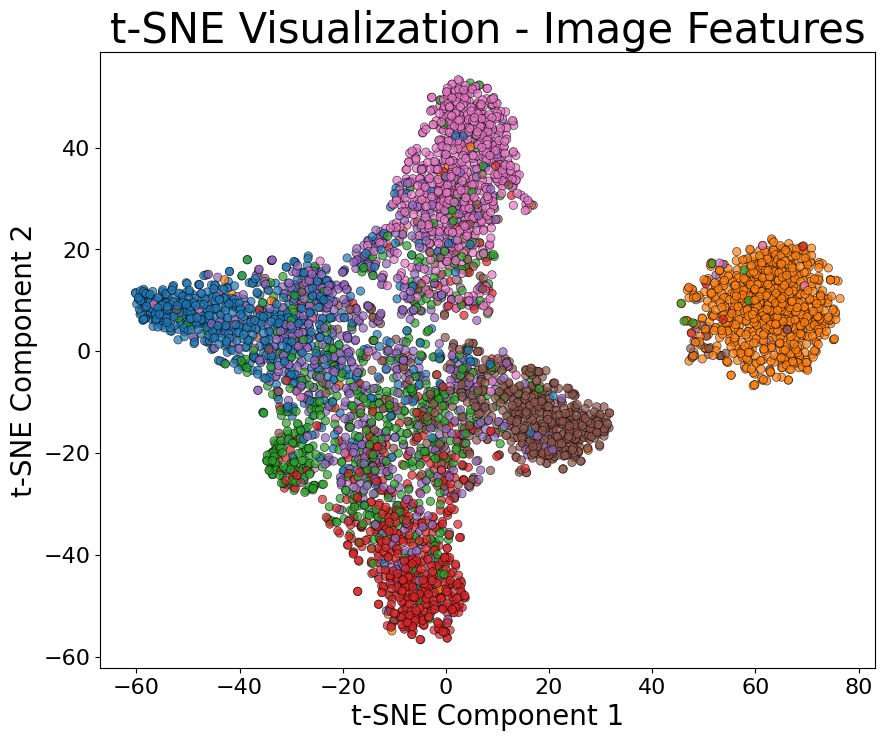


🔹 Applying t-SNE for Landmark Features: (4742, 32)


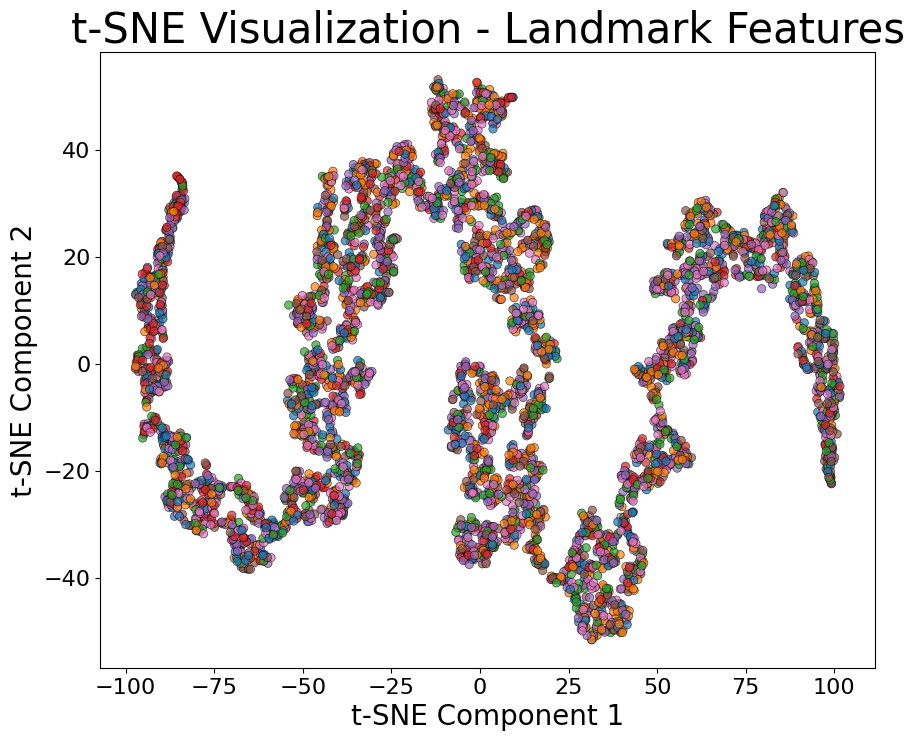


🔹 Applying t-SNE for Z-value Features: (4742, 101)


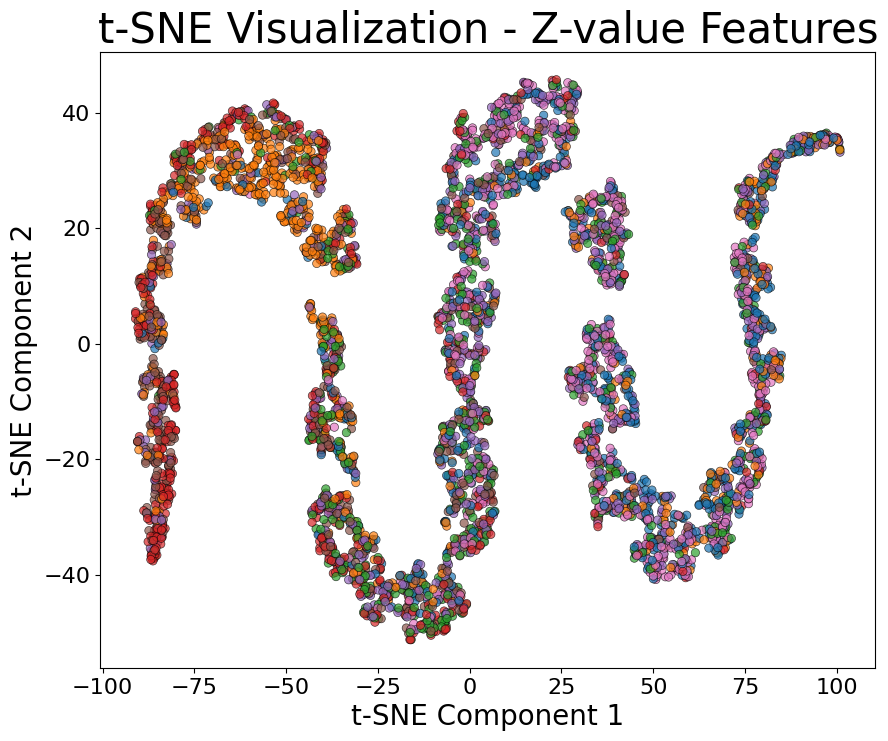

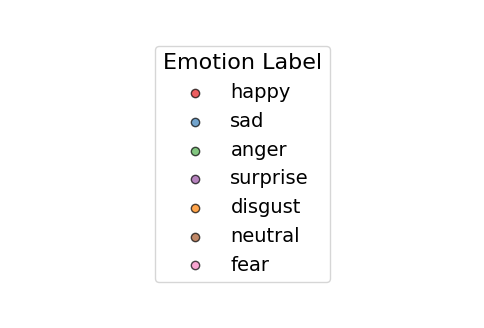

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model

plt.rcParams.update({'font.size': 16})  # 전체 폰트 크기 증가

def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)
    return focal_loss_fixed

# 🔥 1️⃣ 모델 로드
model_path = "/content/drive/MyDrive/02_04_new/Image & Landmark & ZValue_64_64_model.keras"

# 🔥 모델 불러오기 (custom_objects 추가)
model = load_model(model_path, custom_objects={'focal_loss_fixed': focal_loss()})

test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    # 이미지 디코딩 및 크기 조정
    image = tf.io.decode_jpeg(parsed_features["image"], channels=3)
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)  # 흑백 변환

    # 랜드마크 처리
    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])

    # 선택된 랜드마크 인덱스 (추출)
    landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276,
                        33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387,
                        386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311,
                        310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270,
                        409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    selected_landmarks = tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

    # Z-값 조합 계산
    import itertools
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []
    for indices in z_combinations:
        selected_values = tf.gather(parsed_features["z_values"], indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)
    z_product_combinations = tf.stack(z_product_combinations)

    # 레이블 One-Hot 인코딩
    label = tf.one_hot(parsed_features["label"], depth=7)

    return (image, selected_landmarks, z_product_combinations), label


def load_test_dataset(tfrecord_file):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    return dataset

# 🔹 테스트 데이터 가져오기
# num_samples = 1000
# test_dataset = load_test_dataset(test_tfrecord_file).shuffle(buffer_size=4747)
# sample = next(iter(test_dataset.take(num_samples).batch(num_samples)))
# ✅ 모든 데이터 샘플 사용
test_dataset = load_test_dataset(test_tfrecord_file).shuffle(buffer_size=4747)
sample = next(iter(test_dataset.batch(4747)))  # 모든 데이터 가져오기 (4747개)

# 🔹 개별 입력 데이터 추출
images, landmarks, z_values = sample[0]  # (image, landmarks, z_values)
labels = np.argmax(sample[1], axis=1)  # One-hot -> 정수형 라벨 변환

# ✅ **입력 데이터 타입 변환 (Tensor → NumPy)**
landmarks = np.array(landmarks, dtype=np.float32)
z_values = np.array(z_values, dtype=np.float32)

print(f"\n🔹 Shape After Processing:")
print(f"Images: {images.shape}, Landmarks: {landmarks.shape}, Z-values: {z_values.shape}")

### **1️⃣ 이미지 특징 벡터 추출 (CNN Feature)**
feature_extractor_img = tf.keras.Model(
    inputs=model.input[0],  # 이미지 입력
    outputs=model.get_layer("flatten").output  # CNN Feature Layer
)
features_img = feature_extractor_img.predict(images)

### **2️⃣ 랜드마크 특징 벡터 추출 (올바른 Dense Feature)**
feature_extractor_lmk = tf.keras.Model(
    inputs=model.input[1],  # 랜드마크 입력
    outputs=model.get_layer("dense_2").output  # 🔥 랜드마크 관련 Dense 레이어 선택
)
features_lmk = feature_extractor_lmk.predict(landmarks)

### **3️⃣ Z-value 특징 벡터 추출 (Dense Feature)**
feature_extractor_z = tf.keras.Model(
    inputs=model.input[2],  # Z-value 입력
    outputs=model.get_layer("dense_3").output  # 🔥 Z-value 관련 Dense 레이어 선택
)
features_z = feature_extractor_z.predict(z_values)

import numpy as np
import tensorflow as tf
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# ✅ 감정 라벨 매핑 (숫자 → 감정 이름)
emotion_labels = {
    0: "happy", 1: "sad", 2: "anger", 3: "surprise",
    4: "disgust", 5: "neutral", 6: "fear"
}
label_names = [emotion_labels[label] for label in labels]  # 숫자 → 문자열 변환

# ✅ 노란색 제외한 사용자 정의 색상 팔레트 (Set1에서 #FFD700 제거)
custom_palette = [
    "#e41a1c",  # Red (anger)
    "#377eb8",  # Blue (sad)
    "#4daf4a",  # Green (happy)
    "#984ea3",  # Purple (surprise)
    "#ff7f00",  # Orange (disgust)
    "#a65628",  # Brown (neutral)
    "#f781bf"   # Pink (fear)
]

# ✅ **t-SNE 변환 함수**
def apply_tsne(features, labels, title, show_legend=False):
    print(f"\n🔹 Applying t-SNE for {title}: {features.shape}")

    if len(features.shape) > 2:  # 차원 축소 필요 시 Flatten
        features = features.reshape(features.shape[0], -1)

    tsne = TSNE(n_components=2, perplexity=40, max_iter=1500, random_state=42)
    X_tsne = tsne.fit_transform(features)

    # 🔹 시각화 (노란색 제외한 팔레트 적용)
    plt.figure(figsize=(10, 8))
    sns.scatterplot(
        x=X_tsne[:, 0], y=X_tsne[:, 1], hue=[emotion_labels[label] for label in labels],
        alpha=0.7, edgecolor="black", legend=show_legend
    )

    plt.title(f"t-SNE Visualization - {title}", fontsize=30)
    plt.xlabel("t-SNE Component 1", fontsize=20)
    plt.ylabel("t-SNE Component 2", fontsize=20)
    # plt.legend(title="Emotion Label", bbox_to_anchor=(1.05, 1), loc='upper left')  # 범례 위치 조정
    if show_legend:
        plt.legend(title="Emotion Label", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

# ✅ **개별 데이터 t-SNE 적용**
apply_tsne(features_img, labels, "Image Features", show_legend=False)
apply_tsne(features_lmk, labels, "Landmark Features", show_legend=False)
apply_tsne(features_z, labels, "Z-value Features", show_legend=False)

# ✅ **범례만 따로 출력**
def plot_legend():
    plt.figure(figsize=(6, 4))

    # 🔹 감정별 가짜 데이터 생성 (각 클래스에 대해 하나의 점을 찍음)
    for i, (label, color) in enumerate(zip(emotion_labels.values(), custom_palette)):
        plt.scatter([], [], label=label, color=color, alpha=0.7, edgecolor="black")

    # 🔹 범례 표시
    plt.legend(title="Emotion Label", loc='center', fontsize=14)
    plt.axis("off")  # 축 제거
    plt.show()

# ✅ **범례만 출력**
plot_legend()

## Dataset mean / std

In [ ]:
import tensorflow as tf
import numpy as np
import itertools

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

# 랜드마크 인덱스
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276,
                    33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387,
                    386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311,
                    310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270,
                    409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]

# 랜드마크 선택 함수
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

# Z-value 조합 계산
z_combinations = list(itertools.combinations(range(8), 3))

def calculate_z_value_combinations(z_values):
    z_product_combinations = [tf.reduce_prod(tf.gather(z_values, indices)) for indices in z_combinations]
    return tf.stack(z_product_combinations)

# **📌 Z-score 정규화 함수 추가**
def z_score_normalize(data, mu, sigma):
    return (data - mu) / sigma

# **📌 TFRecord 파싱 및 추가 정규화 적용**
def parse_and_prepare_tfrecord(tfrecord, image_mu, image_sigma, landmark_mu, landmark_sigma, z_mu, z_sigma):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    # 📌 이미지 처리 (64x64, 흑백 변환, 초기 정규화 후 추가 정규화)
    image = tf.io.decode_jpeg(parsed_features["image"], channels=1)
    image = tf.image.resize(image, [64, 64])
    image = tf.image.convert_image_dtype(image, tf.float32)  # [0,1] 정규화
    image = z_score_normalize(image, image_mu, image_sigma)  # 추가 정규화

    # 📌 랜드마크 처리 (X, Y, Z 통합 후 정규화)
    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])
    selected_landmarks = z_score_normalize(selected_landmarks, landmark_mu, landmark_sigma)  # 추가 정규화

    # 📌 Z-값 조합 처리 후 정규화
    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)
    z_product_combinations = z_score_normalize(z_product_combinations, z_mu, z_sigma)  # 추가 정규화

    # 레이블 One-Hot 인코딩
    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return (image, selected_landmarks, z_product_combinations), label

# 데이터셋 파일 경로
train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

# **📌 평균 및 표준편차 계산 함수**
def compute_mu_sigma(dataset):
    image_mu, image_sigma = [], []
    landmark_mu, landmark_sigma = [], []
    zvalue_mu, zvalue_sigma = [], []

    for (image_batch, landmark_batch, zvalue_batch), _ in dataset:
        # NumPy 변환
        image_batch = image_batch.numpy()
        landmark_batch = landmark_batch.numpy()
        zvalue_batch = zvalue_batch.numpy()

        # 이미지 평균 및 표준편차 계산
        image_mu.append(np.mean(image_batch))
        image_sigma.append(np.std(image_batch))

        # 랜드마크 전체 평균 및 표준편차 계산
        landmark_mu.append(np.mean(landmark_batch))
        landmark_sigma.append(np.std(landmark_batch))

        # Z-value 평균 및 표준편차
        zvalue_mu.append(np.mean(zvalue_batch))
        zvalue_sigma.append(np.std(zvalue_batch))

    # 최종 평균 및 표준편차 계산
    return {
        "image_mu": np.mean(image_mu), "image_sigma": np.mean(image_sigma),
        "landmark_mu": np.mean(landmark_mu), "landmark_sigma": np.mean(landmark_sigma),
        "z_mu": np.mean(zvalue_mu), "z_sigma": np.mean(zvalue_sigma),
    }

# **📌 평균/표준편차 먼저 계산**
train_stats = compute_mu_sigma(tf.data.TFRecordDataset(train_tfrecord_file).map(lambda x: parse_and_prepare_tfrecord(x, 0, 1, 0, 1, 0, 1)))
val_stats = compute_mu_sigma(tf.data.TFRecordDataset(val_tfrecord_file).map(lambda x: parse_and_prepare_tfrecord(x, 0, 1, 0, 1, 0, 1)))
test_stats = compute_mu_sigma(tf.data.TFRecordDataset(test_tfrecord_file).map(lambda x: parse_and_prepare_tfrecord(x, 0, 1, 0, 1, 0, 1)))

# **📌 최종 데이터셋 로드 (정규화 적용)**
batch_size = 32
train_dataset = tf.data.TFRecordDataset(train_tfrecord_file).map(lambda x: parse_and_prepare_tfrecord(x, **train_stats)).batch(batch_size)
val_dataset = tf.data.TFRecordDataset(val_tfrecord_file).map(lambda x: parse_and_prepare_tfrecord(x, **val_stats)).batch(batch_size)
test_dataset = tf.data.TFRecordDataset(test_tfrecord_file).map(lambda x: parse_and_prepare_tfrecord(x, **test_stats)).batch(batch_size)

# 📌 정규화 후 데이터 확인
print("\n✅ **정규화 후 데이터 통계량**")
for name, stats in zip(["Train", "Validation", "Test"], [train_stats, val_stats, test_stats]):
    print(f"\n📌 {name} Dataset:")
    print(f"  - Image μ: {stats['image_mu']:.4f}, σ: {stats['image_sigma']:.4f}")
    print(f"  - Landmark μ: {stats['landmark_mu']:.6f}, σ: {stats['landmark_sigma']:.6f}")
    print(f"  - Z-Value μ: {stats['z_mu']:.4f}, σ: {stats['z_sigma']:.4f}")



✅ **정규화 후 데이터 통계량**

📌 Train Dataset:
  - Image μ: 103.1029, σ: 57.3697
  - Landmark μ: 0.294650, σ: 0.275316
  - Z-Value μ: 38.2829, σ: 73.9039

📌 Validation Dataset:
  - Image μ: 105.8875, σ: 56.7870
  - Landmark μ: 0.293357, σ: 0.273113
  - Z-Value μ: 34.8804, σ: 66.3852

📌 Test Dataset:
  - Image μ: 105.7389, σ: 56.7857
  - Landmark μ: 0.293131, σ: 0.272971
  - Z-Value μ: 34.9914, σ: 66.6360


In [ ]:
# 데이터셋 리스트를 하나로 합치기
full_dataset = train_dataset.concatenate(val_dataset).concatenate(test_dataset)

# 전체 데이터에서 image, landmark, z-value 평균과 표준편차 계산
image_vals, landmark_vals, z_vals = [], [], []

for (image, landmarks, z_values), _ in full_dataset:
    image_vals.append(tf.reduce_mean(image).numpy())
    landmark_vals.append(tf.reduce_mean(landmarks).numpy())
    z_vals.append(tf.reduce_mean(z_values).numpy())

def summarize(values):
    return f"{np.mean(values):.2f} ± {np.std(values):.2f}"

print("Image:    ", summarize(image_vals))
print("Landmark: ", summarize(landmark_vals))
print("Z-Value:  ", summarize(z_vals))

print("-------")

def summarize_dataset(dataset):
    combined_vals = []
    for (image, landmarks, z_values), _ in dataset:
        v1 = tf.reduce_mean(image).numpy()
        v2 = tf.reduce_mean(landmarks).numpy()
        v3 = tf.reduce_mean(z_values).numpy()
        combined_vals.append(np.mean([v1, v2, v3]))
    return f"{np.mean(combined_vals):.2f} ± {np.std(combined_vals):.2f}"

print("Train:      ", summarize_dataset(train_dataset))
print("Validation: ", summarize_dataset(val_dataset))
print("Test:       ", summarize_dataset(test_dataset))

Image:     -0.00 ± 0.06
Landmark:  -0.00 ± 0.01
Z-Value:   -0.00 ± 0.12
-------
Train:       -0.00 ± 0.04
Validation:  -0.00 ± 0.07
Test:        -0.00 ± 0.07


## t-test: each emotion vs. rest

In [ ]:
import tensorflow as tf
import numpy as np
from scipy.stats import ttest_ind

# 감정 레이블 정의
emotion_labels = {
    0: "Happy",
    1: "Sad",
    2: "Anger",
    3: "Surprise",
    4: "Disgust",
    5: "Neutral",
    6: "Fear",
}

# 랜드마크 선택 인덱스
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276,
                    33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387,
                    386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311,
                    310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270,
                    409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]

# 선택 랜드마크 추출 함수
def extract_selected_landmarks(landmarks):
    selected = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected, [-1])  # 303-dim

# TFRecord 파싱 함수
def parse_tfrecord_all(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed = tf.io.parse_single_example(tfrecord, features)

    # image
    image = tf.io.decode_jpeg(parsed["image"], channels=1)
    image = tf.image.resize(image, [64, 64])
    image = tf.image.convert_image_dtype(image, tf.float32)
    image_mean = tf.reduce_mean(image)

    # landmarks
    landmarks = tf.sparse.to_dense(parsed["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    landmark_mean = tf.reduce_mean(selected_landmarks)

    # z-values
    z_values = parsed["z_values"]
    z_mean = tf.reduce_mean(z_values)

    label = parsed["label"]
    return image_mean, landmark_mean, z_mean, label

# 데이터 로딩 함수
def load_all_values_by_label(tfrecord_file):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_tfrecord_all)

    image_dict = {i: [] for i in range(7)}
    landmark_dict = {i: [] for i in range(7)}
    z_dict = {i: [] for i in range(7)}

    for img_mean, lmk_mean, z_mean, label in dataset:
        label = label.numpy()
        image_dict[label].append(img_mean.numpy())
        landmark_dict[label].append(lmk_mean.numpy())
        z_dict[label].append(z_mean.numpy())

    return image_dict, landmark_dict, z_dict

# TFRecord 경로
train_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

# 데이터 로드 및 병합
img1, lmk1, z1 = load_all_values_by_label(train_file)
img2, lmk2, z2 = load_all_values_by_label(val_file)
img3, lmk3, z3 = load_all_values_by_label(test_file)

image_dict = {i: img1[i] + img2[i] + img3[i] for i in range(7)}
landmark_dict = {i: lmk1[i] + lmk2[i] + lmk3[i] for i in range(7)}
z_dict = {i: z1[i] + z2[i] + z3[i] for i in range(7)}

# t-test 함수
def perform_t_test_per_emotion(data_dict, title):
    print(f"\n📊 {title} - T-test 결과 (1 vs 6 감정)")
    for label_idx in range(7):
        group1 = data_dict[label_idx]
        group2 = []
        for other_idx in range(7):
            if other_idx != label_idx:
                group2 += data_dict[other_idx]
        t_stat, p_val = ttest_ind(group1, group2, equal_var=False)
        print(f"{emotion_labels[label_idx]} vs Others: t = {t_stat:.3f}, p = {p_val:.4f}")

# 수행
perform_t_test_per_emotion(image_dict, "Image Mean")
perform_t_test_per_emotion(landmark_dict, "Landmark Mean")
perform_t_test_per_emotion(z_dict, "Z-value Mean")



📊 Image Mean - T-test 결과 (1 vs 6 감정)
Happy vs Others: t = 3.451, p = 0.0006
Sad vs Others: t = 0.157, p = 0.8750
Anger vs Others: t = -3.335, p = 0.0009
Surprise vs Others: t = -1.182, p = 0.2371
Disgust vs Others: t = -2.122, p = 0.0338
Neutral vs Others: t = 3.975, p = 0.0001
Fear vs Others: t = -1.268, p = 0.2049

📊 Landmark Mean - T-test 결과 (1 vs 6 감정)
Happy vs Others: t = -3.546, p = 0.0004
Sad vs Others: t = 1.529, p = 0.1262
Anger vs Others: t = 14.200, p = 0.0000
Surprise vs Others: t = -14.744, p = 0.0000
Disgust vs Others: t = 0.031, p = 0.9754
Neutral vs Others: t = -0.490, p = 0.6238
Fear vs Others: t = 2.108, p = 0.0350

📊 Z-value Mean - T-test 결과 (1 vs 6 감정)
Happy vs Others: t = -10.904, p = 0.0000
Sad vs Others: t = 37.371, p = 0.0000
Anger vs Others: t = -48.713, p = 0.0000
Surprise vs Others: t = -94.661, p = 0.0000
Disgust vs Others: t = 11.437, p = 0.0000
Neutral vs Others: t = 42.486, p = 0.0000
Fear vs Others: t = 3.520, p = 0.0004


## Gender & age per emotion

In [2]:
import os
from collections import defaultdict

# 감정별 디렉토리 경로
emotion_directories = {
    "anger": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_anger",
    "disgust": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_disgust",
    "fear": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_fear",
    "happy": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_happy",
    "neutral": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_neutral",
    "sad": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_sad",
    "surprise": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_surprise"
}

# 결과 저장 딕셔너리
results = {}

for emotion, path in emotion_directories.items():
    gender_count = {"male": 0, "female": 0}
    age_count = defaultdict(int)

    files = os.listdir(path)
    for filename in files:
        if "_│▓_" in filename:  # 남성
            gender_count["male"] += 1
        elif "_┐й_" in filename:  # 여성
            gender_count["female"] += 1

        # 연령대 추출 (예: _20_ 또는 _30_)
        for age in ["10", "20", "30", "40", "50", "60"]:
            if f"_{age}_" in filename:
                age_count[age] += 1
                break  # 첫 번째 매칭만 카운트

    results[emotion] = {
        "gender": gender_count,
        "age": dict(age_count)
    }

# 결과 출력
for emotion in results:
    print(f"\n📂 Emotion: {emotion.capitalize()}")
    print("👫 Gender Count:")
    for gender, count in results[emotion]["gender"].items():
        print(f"  {gender}: {count}")
    print("📅 Age Group Count:")
    for age, count in sorted(results[emotion]["age"].items()):
        print(f"  {age}s: {count}")



📂 Emotion: Anger
👫 Gender Count:
  male: 3008
  female: 3562
...
  40s: 922
  50s: 214
  60s: 22

📂 Emotion: Neutral
👫 Gender Count:
  male: 3330
  female: 4037
📅 Age Group Count:
  10s: 66
  20s: 3642
  30s: 2570
  40s: 898
  50s: 166
  60s: 25

📂 Emotion: Sad
👫 Gender Count:
  male: 2884
  female: 3817
📅 Age Group Count:
  10s: 89
  20s: 3302
  30s: 2372
  40s: 766
  50s: 158
  60s: 14

📂 Emotion: Surprise
👫 Gender Count:
  male: 2819
  female: 3085
📅 Age Group Count:
  10s: 67
  20s: 2922
  30s: 2092
  40s: 657
  50s: 161
  60s: 5


## Odds ratio per emotion

    Emotion   Odds Ratio     CI Lower     CI Upper 95% CI (Lower - Upper)  \
0     happy  3624.225564  2114.658851  6211.408963      2114.66 - 6211.41   
1       sad    51.516856    41.134499    64.519721          41.13 - 64.52   
2     anger    68.023589    53.671877    86.212909          53.67 - 86.21   
3  surprise    63.224599    49.898586    80.109482          49.90 - 80.11   
4   disgust     8.045930     6.665531     9.712203            6.67 - 9.71   
5   neutral   207.039987   155.231872   276.138886        155.23 - 276.14   
6      fear    12.528535    10.298664    15.241218          10.30 - 15.24   

         P-value  
0   0.000000e+00  
1   0.000000e+00  
2   0.000000e+00  
3   0.000000e+00  
4  6.743678e-129  
5   0.000000e+00  
6  9.973657e-190  


<ipython-input-57-e86482af49d3>:148: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Emotion", y="Odds Ratio", palette="viridis")


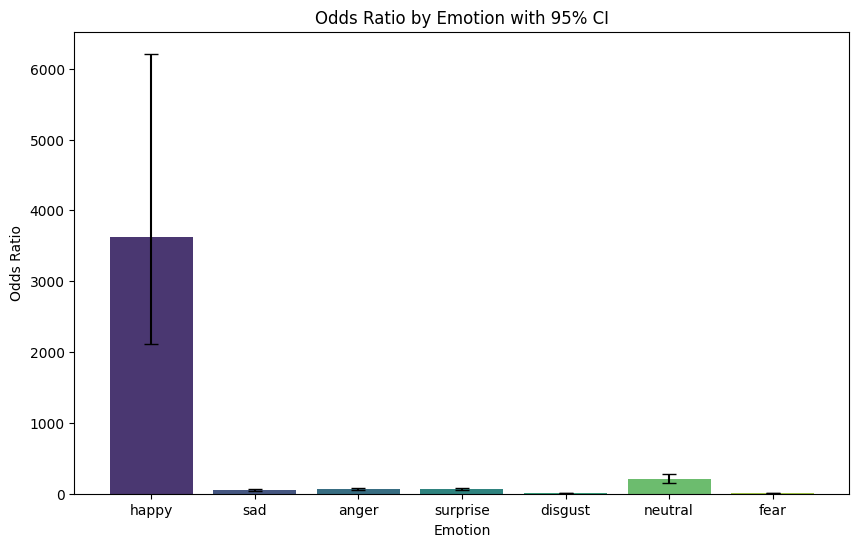

In [ ]:
import numpy as np
import tensorflow as tf
import itertools
from sklearn.metrics import confusion_matrix
from scipy.stats import chi2_contingency
from math import log, sqrt, exp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

# 랜드마크 인덱스 정의
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]

# 랜드마크 추출 함수
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

# Z 값 조합 계산 함수
def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    # 이미지 디코딩 및 크기 조정 (64x64 유지, RGB 그대로 유지)
    image = tf.io.decode_jpeg(parsed_features["image"], channels=3)
    image = tf.image.resize(image, [64, 64])  # 🔹 64x64 크기로 변경
    image = tf.image.rgb_to_grayscale(image)  # 🔹 흑백 변환

    # 랜드마크 처리
    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    # 레이블 One-Hot 인코딩
    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    # Z-값 조합 계산
    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, selected_landmarks, z_product_combinations), label

# 데이터셋 로드 및 준비 함수
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

train_dataset = load_and_prepare_dataset(train_tfrecord_file, 16)
val_dataset = load_and_prepare_dataset(val_tfrecord_file, 16)
test_dataset = load_and_prepare_dataset(test_tfrecord_file, 16)

# 모델 불러오기
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)
    return focal_loss_fixed

model_path = "/content/drive/MyDrive/02_04_new/Image & Landmark & ZValue_64_64_model.keras"
model = load_model(model_path, custom_objects={'focal_loss_fixed': focal_loss()}, compile=False)
# 예측 수행
# -------------------------------------------------
# 예측 결과를 이용하여 감정별 Odds Ratio, 95% CI, P-value 계산
# -------------------------------------------------
# 예측 결과를 이용하여 감정별 Odds Ratio, 95% CI, P-value 계산
results = []
for emotion, idx in emotion_labels.items():
    # True/False Positive/Negative 계산
    TP = np.sum((np.array(all_predictions) == idx) & (np.array(all_true_labels) == idx))
    FP = np.sum((np.array(all_predictions) == idx) & (np.array(all_true_labels) != idx))
    FN = np.sum((np.array(all_predictions) != idx) & (np.array(all_true_labels) == idx))
    TN = np.sum((np.array(all_predictions) != idx) & (np.array(all_true_labels) != idx))

    # 0인 경우엔 smoothing 처리
    if TP == 0 or TN == 0 or FP == 0 or FN == 0:
        TP += 1
        FP += 1
        FN += 1
        TN += 1

    # Odds Ratio 계산
    odds_ratio = (TP * TN) / (FP * FN)

    # 표준오차 계산
    se = sqrt(1/TP + 1/TN + 1/FP + 1/FN)
    z = 1.96  # 95% 신뢰구간 (z값)
    log_or = log(odds_ratio)
    ci_lower = exp(log_or - z * se)
    ci_upper = exp(log_or + z * se)

    # chi2_contingency를 통해 p-value 계산
    _, p_value, _, _ = chi2_contingency([[TP, FP], [FN, TN]])

    results.append({
        "Emotion": emotion,
        "Odds Ratio": odds_ratio,
        "CI Lower": ci_lower,
        "CI Upper": ci_upper,
        "95% CI (Lower - Upper)": f"{ci_lower:.2f} - {ci_upper:.2f}",
        "P-value": p_value
    })

# DataFrame 생성 및 출력 (표)
df = pd.DataFrame(results)
print(df)

# -------------------------------------------------
# 그래프: 감정별 Odds Ratio와 95% 신뢰구간 (에러바 포함) 막대그래프

# 에러바 계산: 에러바는 각각 (Odds Ratio - CI Lower)와 (CI Upper - Odds Ratio)
df['Error Lower'] = df['Odds Ratio'] - df['CI Lower']
df['Error Upper'] = df['CI Upper'] - df['Odds Ratio']
error_bars = [df['Error Lower'], df['Error Upper']]

plt.figure(figsize=(10,6))
sns.barplot(data=df, x="Emotion", y="Odds Ratio", palette="viridis")
plt.errorbar(x=np.arange(len(df)), y=df["Odds Ratio"], yerr=error_bars, fmt='none', c='black', capsize=5)
plt.title("Odds Ratio by Emotion with 95% CI")
plt.xlabel("Emotion")
plt.ylabel("Odds Ratio")
plt.show()

In [ ]:
print(df.to_latex(index=False))


\begin{tabular}{lrrrlrrr}
\toprule
Emotion & Odds Ratio & CI Lower & CI Upper & 95% CI (Lower - Upper) & P-value & Error Lower & Error Upper \\
\midrule
happy & 3624.225564 & 2114.658851 & 6211.408963 & 2114.66 - 6211.41 & 0.000000 & 1509.566713 & 2587.183399 \\
sad & 51.516856 & 41.134499 & 64.519721 & 41.13 - 64.52 & 0.000000 & 10.382356 & 13.002865 \\
anger & 68.023589 & 53.671877 & 86.212909 & 53.67 - 86.21 & 0.000000 & 14.351712 & 18.189320 \\
surprise & 63.224599 & 49.898586 & 80.109482 & 49.90 - 80.11 & 0.000000 & 13.326013 & 16.884883 \\
disgust & 8.045930 & 6.665531 & 9.712203 & 6.67 - 9.71 & 0.000000 & 1.380399 & 1.666273 \\
neutral & 207.039987 & 155.231872 & 276.138886 & 155.23 - 276.14 & 0.000000 & 51.808115 & 69.098899 \\
fear & 12.528535 & 10.298664 & 15.241218 & 10.30 - 15.24 & 0.000000 & 2.229870 & 2.712683 \\
\bottomrule
\end{tabular}



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46321 (\N{HANGUL SYLLABLE DEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
...
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47582 (\N{HANGUL SYLLABLE MAJ}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


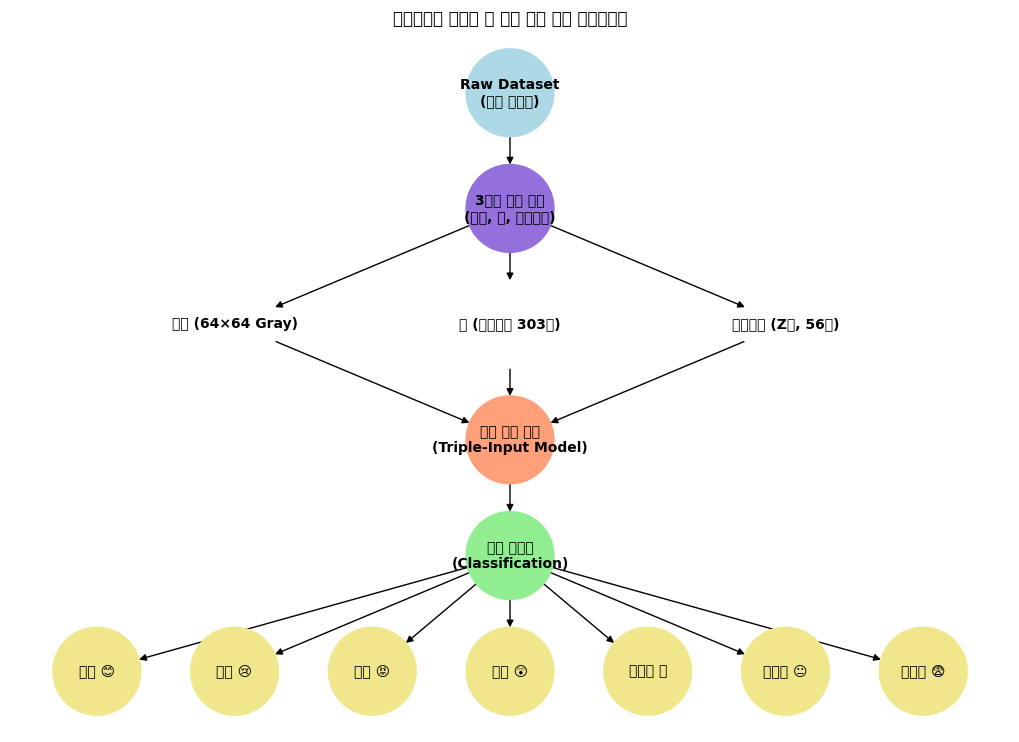

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

# 새로운 그래프 생성
G = nx.DiGraph()

# 노드 추가 (더 직관적인 용어 사용)
nodes = {
    "Raw Dataset\n(얼굴 이미지)": "lightblue",
    "3가지 정보 뽑기\n(사진, 점, 거리비율)": "mediumpurple",
    "사진 (64×64 Gray)": "white",
    "점 (랜드마크 303개)": "white",
    "거리비율 (Z값, 56개)": "white",
    "감정 분석 모델\n(Triple-Input Model)": "lightsalmon",
    "감정 맞히기\n(Classification)": "lightgreen",
    "행복 😊": "khaki",
    "슬픔 😢": "khaki",
    "화남 😡": "khaki",
    "놀람 😲": "khaki",
    "역겨움 🤢": "khaki",
    "무표정 😐": "khaki",
    "두려움 😨": "khaki",
}

# 노드 위치 설정
pos = {
    "Raw Dataset\n(얼굴 이미지)": (3, 6),
    "3가지 정보 뽑기\n(사진, 점, 거리비율)": (3, 5),
    "사진 (64×64 Gray)": (1, 4),
    "점 (랜드마크 303개)": (3, 4),
    "거리비율 (Z값, 56개)": (5, 4),
    "감정 분석 모델\n(Triple-Input Model)": (3, 3),
    "감정 맞히기\n(Classification)": (3, 2),
    "행복 😊": (0, 1),
    "슬픔 😢": (1, 1),
    "화남 😡": (2, 1),
    "놀람 😲": (3, 1),
    "역겨움 🤢": (4, 1),
    "무표정 😐": (5, 1),
    "두려움 😨": (6, 1),
}

# 간선 추가 (데이터 흐름)
edges = [
    ("Raw Dataset\n(얼굴 이미지)", "3가지 정보 뽑기\n(사진, 점, 거리비율)"),
    ("3가지 정보 뽑기\n(사진, 점, 거리비율)", "사진 (64×64 Gray)"),
    ("3가지 정보 뽑기\n(사진, 점, 거리비율)", "점 (랜드마크 303개)"),
    ("3가지 정보 뽑기\n(사진, 점, 거리비율)", "거리비율 (Z값, 56개)"),
    ("사진 (64×64 Gray)", "감정 분석 모델\n(Triple-Input Model)"),
    ("점 (랜드마크 303개)", "감정 분석 모델\n(Triple-Input Model)"),
    ("거리비율 (Z값, 56개)", "감정 분석 모델\n(Triple-Input Model)"),
    ("감정 분석 모델\n(Triple-Input Model)", "감정 맞히기\n(Classification)"),
    ("감정 맞히기\n(Classification)", "행복 😊"),
    ("감정 맞히기\n(Classification)", "슬픔 😢"),
    ("감정 맞히기\n(Classification)", "화남 😡"),
    ("감정 맞히기\n(Classification)", "놀람 😲"),
    ("감정 맞히기\n(Classification)", "역겨움 🤢"),
    ("감정 맞히기\n(Classification)", "무표정 😐"),
    ("감정 맞히기\n(Classification)", "두려움 😨"),
]

# 그래프에 노드 및 엣지 추가
G.add_nodes_from(nodes.keys())
G.add_edges_from(edges)

# 그래프 그리기
plt.figure(figsize=(10, 7))
node_colors = [nodes[node] for node in G.nodes]
nx.draw(
    G, pos, with_labels=True, node_color=node_colors, edge_color="black",
    node_size=4000, font_size=10, font_weight="bold", arrows=True
)

# 그래프 출력
plt.title("초등학생도 이해할 수 있는 감정 분석 프레임워크", fontsize=12, fontweight="bold")
plt.show()


## Hyperparameter ablation

In [ ]:
import os
import tensorflow as tf
import numpy as np
import pandas as pd
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, Dense, BatchNormalization, Activation, MaxPooling2D, Dropout, Flatten, Add, Concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, CSVLogger, ModelCheckpoint
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, precision_recall_curve, auc
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음


# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Dense, Dropout, BatchNormalization,
                                     Conv2D, MaxPooling2D, Flatten, Activation, Concatenate)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import itertools
from tensorflow.keras.regularizers import l2
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, roc_curve, auc
import pandas as pd


# 🟢 Ablation Study Configurations (Modified Parameters)
ablation_configs = [

    # 🔹 Learning Rate Ablation
    {"name": "low_lr", "batch_size": 32, "lr": 1e-4, "dropout": 0.3, "l2_reg": 0.005, "residual_blocks": 3},  # 낮은 학습률
    {"name": "high_lr", "batch_size": 32, "lr": 1e-3, "dropout": 0.3, "l2_reg": 0.005, "residual_blocks": 3},  # 높은 학습률

    # 🔹 Dropout Ablation
    {"name": "low_dropout", "batch_size": 32, "lr": 5e-4, "dropout": 0.1, "l2_reg": 0.005, "residual_blocks": 3},  # 낮은 Dropout
    {"name": "high_dropout", "batch_size": 32, "lr": 5e-4, "dropout": 0.5, "l2_reg": 0.005, "residual_blocks": 3},  # 높은 Dropout

    # 🔹 L2 Regularization Ablation
    {"name": "low_l2", "batch_size": 32, "lr": 5e-4, "dropout": 0.3, "l2_reg": 0.001, "residual_blocks": 3},  # 낮은 L2 정규화
    {"name": "high_l2", "batch_size": 32, "lr": 5e-4, "dropout": 0.3, "l2_reg": 0.01, "residual_blocks": 3},  # 높은 L2 정규화

    # 🔹 Residual Block Ablation
    {"name": "fewer_residuals", "batch_size": 32, "lr": 5e-4, "dropout": 0.3, "l2_reg": 0.005, "residual_blocks": 1},  # Residual Block 감소
    {"name": "more_residuals", "batch_size": 32, "lr": 5e-4, "dropout": 0.3, "l2_reg": 0.005, "residual_blocks": 5},  # Residual Block 증가

]



# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)
batch_size = 32

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    # 이미지 디코딩 및 크기 조정 (64x64 유지, RGB 그대로 유지)
    image = tf.io.decode_jpeg(parsed_features["image"], channels=3)
    image = tf.image.resize(image, [64, 64])  # 🔹 64x64 크기로 변경
    image = tf.image.rgb_to_grayscale(image)  # 🔹 흑백 변환

    # 랜드마크 처리
    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    # 레이블 One-Hot 인코딩
    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    # Z-값 조합 계산
    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, selected_landmarks, z_product_combinations), label

# 🟢 데이터 증강 함수 수정 (매개변수 구조 맞춤)
def augment(inputs, label):
    image, landmarks, z_values = inputs  # 튜플 언패킹
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    return (image, landmarks, z_values), label

# 🟢 데이터셋 로드 및 증강 적용
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)

    # 🔥 증강 적용 시 매개변수 개수 맞춤
    dataset = dataset.map(augment)

    if batch_size:
        dataset = dataset.batch(batch_size)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)  # 데이터 병렬 로드 최적화
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

# 🔹 수정된 데이터셋 로드 호출
train_dataset = load_and_prepare_dataset(train_tfrecord_file, batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file, batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file, batch_size)


# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (64, 64, 1)  # 이미지 데이터의 형태 (수정됨)
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원

# 🔹 Train dataset sample size
train_samples = 71002

# 🟢 Training Loop for Ablation Study
for config in ablation_configs:
    print(f"\n🔵 Running Experiment: {config['name']}\n")

    # 🟠 Model Inputs
    model_image_input = Input(shape=(64, 64, 1))
    model_landmark_input = Input(shape=(303,))
    model_z_input = Input(shape=(56,))

    # 🟠 Image Processing Path
    x_image = Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal')(model_image_input)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)
    x_image = MaxPooling2D((2,2))(x_image)
    x_image = Dropout(config["dropout"])(x_image)

    x_image = Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)
    x_image = MaxPooling2D((2,2))(x_image)
    x_image = Dropout(config["dropout"])(x_image)

    for _ in range(config["residual_blocks"]):
        shortcut = x_image
        x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
        x_image = BatchNormalization()(x_image)
        x_image = Activation('relu')(x_image)
        x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
        x_image = BatchNormalization()(x_image)
        shortcut = Conv2D(256, (1,1), padding='same', kernel_initializer='he_normal')(shortcut)
        shortcut = BatchNormalization()(shortcut)
        x_image = Add()([x_image, shortcut])
        x_image = Activation('relu')(x_image)
        x_image = Dropout(config["dropout"])(x_image)

    x_image = MaxPooling2D((2,2))(x_image)
    x_image = Flatten()(x_image)

    # 🟠 Landmark and Z-Value Processing
    x_landmark = Dense(101, kernel_regularizer=l2(config["l2_reg"]), kernel_initializer='he_normal')(model_landmark_input)
    x_landmark = BatchNormalization()(x_landmark)
    x_landmark = Activation('elu')(x_landmark)
    x_landmark = Dropout(config["dropout"])(x_landmark)

    x_z = Dense(101, kernel_regularizer=l2(config["l2_reg"]), kernel_initializer='he_normal')(model_z_input)
    x_z = BatchNormalization()(x_z)
    x_z = Activation('elu')(x_z)
    x_z = Dropout(config["dropout"])(x_z)

    # 🟠 Merge Paths
    combined = Concatenate()([x_image, x_landmark, x_z])
    combined = Dense(128, kernel_regularizer=l2(config["l2_reg"]), kernel_initializer='he_normal')(combined)
    combined = BatchNormalization()(combined)
    combined = Activation('elu')(combined)
    combined = Dropout(config["dropout"])(combined)

    # 🟠 Output Layer
    model_output = Dense(7, activation='softmax', kernel_regularizer=l2(config["l2_reg"]))(combined)

    # 🟢 Model Compilation
    model = Model(inputs=[model_image_input, model_landmark_input, model_z_input], outputs=model_output)
    model.compile(optimizer=Adam(learning_rate=config["lr"]), loss="categorical_crossentropy", metrics=['accuracy'])

    # 🟢 Model Saving Directory
    model_dir = f"ablation_results/{config['name']}"
    os.makedirs(model_dir, exist_ok=True)

    # 🟢 Callbacks
    csv_logger = CSVLogger(f"{model_dir}/training_log.csv", append=True)
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
    checkpoint = ModelCheckpoint(f"{model_dir}/model.keras", save_best_only=True, monitor="val_loss")

    # 🟢 Training
    history = model.fit(
        train_dataset,
        steps_per_epoch=train_samples // config["batch_size"],
        validation_data=val_dataset,
        callbacks=[early_stopping, reduce_lr, csv_logger, checkpoint],
        epochs=200
    )

    # 🟢 Save Model
    model.save(f"{model_dir}/final_model.keras")

# 🟢 Evaluation Function
def evaluate_model(model, model_name):
    y_pred_probs = model.predict(test_dataset)
    y_pred = np.argmax(y_pred_probs, axis=1)

    y_true = tf.concat([y for _, y in test_dataset], axis=0)
    y_true = np.argmax(y_true.numpy(), axis=1)  # One-hot을 정수 라벨로 변환

    conf_matrix = confusion_matrix(y_true, y_pred)
    class_report = classification_report(y_true, y_pred, output_dict=True)

    # 🟠 Save Results
    model_dir = f"ablation_results/{model_name}"
    pd.DataFrame(conf_matrix).to_csv(f"{model_dir}/confusion_matrix.csv")
    pd.DataFrame(class_report).to_csv(f"{model_dir}/classification_report.csv")

    print(f"✅ Evaluation results saved for {model_name}")

# 🔹 Load and Evaluate Models
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, precision_recall_curve, auc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             precision_recall_curve, average_precision_score, roc_curve, auc,
                             precision_score, recall_score, f1_score)
from sklearn.preprocessing import label_binarize
import tensorflow as tf
import os

# 🎯 Ablation Study Results Processing
for config in ablation_configs:
    model_name = config['name']
    model_dir = f"ablation_results/{model_name}"

    # 📌 1. Load Training Log
    log_path = f"{model_dir}/training_log.csv"
    df = pd.read_csv(log_path)

    # 🔹 Loss & Accuracy Graph 저장
    plt.figure(figsize=(12, 5))

    # Loss Curve
    plt.subplot(1, 2, 1)
    plt.plot(df['epoch'], df['loss'], label='Train Loss', linestyle='dashed')
    plt.plot(df['epoch'], df['val_loss'], label='Validation Loss')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Loss Curve - {model_name}")
    plt.legend()
    plt.savefig(f"{model_dir}/loss_curve.png")

    # Accuracy Curve
    plt.subplot(1, 2, 2)
    plt.plot(df['epoch'], df['accuracy'], label='Train Accuracy', linestyle='dashed')
    plt.plot(df['epoch'], df['val_accuracy'], label='Validation Accuracy')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy Curve - {model_name}")
    plt.legend()
    plt.savefig(f"{model_dir}/accuracy_curve.png")
    plt.close()

    # 📌 2. Load Model and Evaluation Data
    model = tf.keras.models.load_model(f"{model_dir}/final_model.keras")
    y_pred_probs = model.predict(test_dataset)
    y_pred = np.argmax(y_pred_probs, axis=1)

    y_true = tf.concat([y for _, y in test_dataset], axis=0).numpy()
    y_true = np.argmax(y_true, axis=1)  # One-hot을 정수 라벨로 변환
    y_true_onehot = label_binarize(y_true, classes=np.arange(7))

    # 📌 3. Compute Classification Metrics
    precision = precision_score(y_true, y_pred, average='macro')
    recall = recall_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='macro')
    roc_auc = roc_auc_score(y_true_onehot, y_pred_probs, multi_class='ovr', average="macro")

    print(f"{model_name} - Precision: {precision:.2f}, Recall: {recall:.2f}, F1 Score: {f1:.2f}, ROC AUC: {roc_auc:.2f}")

    # 📌 4. Confusion Matrix (CSV & Heatmap)
    conf_matrix = confusion_matrix(y_true, y_pred)
    pd.DataFrame(conf_matrix).to_csv(f"{model_dir}/confusion_matrix.csv", index=False)

    plt.figure(figsize=(6, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.savefig(f"{model_dir}/confusion_matrix.png")
    plt.close()

    # 📌 5. Precision-Recall & ROC Curves per Class
    precision_dict, recall_dict, ap_dict = {}, {}, {}
    fpr_dict, tpr_dict, auc_dict = {}, {}, {}

    plt.figure(figsize=(10, 6))
    for i, emotion in enumerate(emotion_labels):
        precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_true_onehot[:, i], y_pred_probs[:, i])
        ap_dict[emotion] = average_precision_score(y_true_onehot[:, i], y_pred_probs[:, i])
        plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2, label=f'{emotion} (AP={ap_dict[emotion]:.2f})')

    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve - {model_name}')
    plt.legend(loc="best")
    plt.savefig(f"{model_dir}/precision_recall_curve.png")
    plt.close()

    plt.figure(figsize=(10, 6))
    for i, emotion in enumerate(emotion_labels):
        fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_true_onehot[:, i], y_pred_probs[:, i])
        auc_dict[emotion] = auc(fpr_dict[emotion], tpr_dict[emotion])
        plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (AUC={auc_dict[emotion]:.2f})')

    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('1 - Specificity')
    plt.ylabel('Sensitivity')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc="best")
    plt.savefig(f"{model_dir}/roc_curve.png")
    plt.close()

    # 📌 6. Save PR & ROC Data
    pr_curve_data = []
    roc_curve_data = []

    for i, emotion in enumerate(emotion_labels):
        pr_curve_data.extend([{ 'Model': model_name, 'Emotion': emotion, 'AP': ap_dict[emotion], 'Recall': r, 'Precision': p }
                               for r, p in zip(recall_dict[emotion], precision_dict[emotion])])
        roc_curve_data.extend([{ 'Model': model_name, 'Emotion': emotion, 'AUC': auc_dict[emotion], 'FPR': f, 'TPR': t }
                                for f, t in zip(fpr_dict[emotion], tpr_dict[emotion])])

    pd.DataFrame(pr_curve_data).to_csv(f"{model_dir}/precision_recall_data.csv", index=False)
    pd.DataFrame(roc_curve_data).to_csv(f"{model_dir}/roc_curve_data.csv", index=False)

    print(f"✅ Results saved for {model_name}")

print("\n🎯 **Ablation Study Analysis Complete!**")

print("\n🎯 **Ablation Study Analysis Complete!**")



🔵 Running Experiment: low_lr

Epoch 1/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 62s 19ms/step - accuracy: 0.3104 - loss: 4.3422 - val_accuracy: 0.4503 - val_loss: 2.5031 - learning_rate: 1.0000e-04
...
Epoch 37/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 63s 28ms/step - accuracy: 0.7354 - loss: 0.7509 - val_accuracy: 0.6960 - val_loss: 0.8656 - learning_rate: 2.5000e-04
Epoch 38/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 2s 816us/step - accuracy: 0.8077 - loss: 0.6274 - val_accuracy: 0.6976 - val_loss: 0.8682 - learning_rate: 2.5000e-04
Epoch 39/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 63s 28ms/step - accuracy: 0.7422 - loss: 0.7341 - val_accuracy: 0.6885 - val_loss: 0.8926 - learning_rate: 2.5000e-04
Epoch 40/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 2s 836us/step - accuracy: 0.7308 - loss: 0.7078 - val_accuracy: 0.6874 - val_loss: 0.8920 - learning_rate: 1.2500e-04
Epoch 41/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 64s 29ms/step - accuracy: 0.7519 - loss: 0.6998 - val_accuracy: 0.7036 - val_loss: 0.8488 - learning_rate: 1.250

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


low_lr - Precision: 0.67, Recall: 0.68, F1 Score: 0.67, ROC AUC: 0.93
✅ Results saved for low_lr
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


high_lr - Precision: 0.70, Recall: 0.69, F1 Score: 0.69, ROC AUC: 0.93
✅ Results saved for high_lr
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step


...

high_l2 - Precision: 0.70, Recall: 0.69, F1 Score: 0.69, ROC AUC: 0.93
✅ Results saved for high_l2
149/149 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


fewer_residuals - Precision: 0.68, Recall: 0.69, F1 Score: 0.68, ROC AUC: 0.93
✅ Results saved for fewer_residuals
149/149 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


more_residuals - Precision: 0.69, Recall: 0.70, F1 Score: 0.69, ROC AUC: 0.93
✅ Results saved for more_residuals

🎯 **Ablation Study Analysis Complete!**

🎯 **Ablation Study Analysis Complete!**


In [ ]:
import os
import tensorflow as tf
import numpy as np
import pandas as pd
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, Dense, BatchNormalization, Activation, MaxPooling2D, Dropout, Flatten, Add, Concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, CSVLogger, ModelCheckpoint
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, precision_recall_curve, auc
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음


# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Dense, Dropout, BatchNormalization,
                                     Conv2D, MaxPooling2D, Flatten, Activation, Concatenate)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import itertools
from tensorflow.keras.regularizers import l2
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, roc_curve, auc
import pandas as pd

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)
batch_size = 32

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    # 이미지 디코딩 및 크기 조정 (64x64 유지, RGB 그대로 유지)
    image = tf.io.decode_jpeg(parsed_features["image"], channels=3)
    image = tf.image.resize(image, [64, 64])  # 🔹 64x64 크기로 변경
    image = tf.image.rgb_to_grayscale(image)  # 🔹 흑백 변환

    # 랜드마크 처리
    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    # 레이블 One-Hot 인코딩
    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    # Z-값 조합 계산
    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, selected_landmarks, z_product_combinations), label

# 🟢 데이터 증강 함수 수정 (매개변수 구조 맞춤)
def augment(inputs, label):
    image, landmarks, z_values = inputs  # 튜플 언패킹
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    return (image, landmarks, z_values), label

# 🟢 데이터셋 로드 및 증강 적용
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)

    # 🔥 증강 적용 시 매개변수 개수 맞춤
    dataset = dataset.map(augment)

    if batch_size:
        dataset = dataset.batch(batch_size)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)  # 데이터 병렬 로드 최적화
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

# 🔹 수정된 데이터셋 로드 호출
train_dataset = load_and_prepare_dataset(train_tfrecord_file, batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file, batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file, batch_size)


# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (64, 64, 1)  # 이미지 데이터의 형태 (수정됨)
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원

# 🔹 Train dataset sample size
train_samples = 71002

# 🟢 모델 평가 함수
def evaluate_model(model, model_name):
    print(f"\n🔹 Evaluating Model: {model_name}")

    # 모델 예측 수행
    y_pred_probs = model.predict(test_dataset)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # 실제 정답값 변환
    y_true = tf.concat([y for _, y in test_dataset], axis=0).numpy()
    y_true = np.argmax(y_true, axis=1)  # One-hot을 정수 라벨로 변환

    # 성능 평가
    loss, accuracy = model.evaluate(test_dataset, verbose=0)
    precision = precision_score(y_true, y_pred, average='macro')
    recall = recall_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='macro')

    # 클래스별 정확도 계산
    class_accuracies = {}
    for i, label in enumerate(emotion_labels):
        class_mask = (y_true == i)
        if np.sum(class_mask) > 0:  # 해당 클래스가 존재하는 경우만 계산
            class_accuracies[label] = np.mean(y_pred[class_mask] == y_true[class_mask])
        else:
            class_accuracies[label] = 0.0

    # ROC AUC Score 계산
    y_true_onehot = tf.keras.utils.to_categorical(y_true, num_classes)
    roc_auc = roc_auc_score(y_true_onehot, y_pred_probs, multi_class='ovr', average="macro")

    # 결과 출력
    print(f"\n🔹 Test Loss: {loss:.5f}")
    print(f"🔹 Test Accuracy: {accuracy:.5f}")
    for label, acc in class_accuracies.items():
        print(f"🔹 Accuracy for {label}: {acc:.2f}")

    print(f"\n🔹 Precision: {precision:.2f}")
    print(f"🔹 Recall: {recall:.2f}")
    print(f"🔹 F1 Score: {f1:.2f}")

    print(f"\n🔹 ROC AUC Score: {roc_auc:.2f}")

    return {
        "model_name": model_name,
        "test_loss": loss,
        "test_accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "roc_auc": roc_auc,
        "class_accuracies": class_accuracies
    }

# 🟢 Google Drive 내 저장된 모든 모델 불러와서 평가
all_results = []
for model_name in os.listdir(ablation_results_dir):
    model_path = os.path.join(ablation_results_dir, model_name, "final_model.keras")

    if os.path.exists(model_path):
        model = tf.keras.models.load_model(model_path)
        results = evaluate_model(model, model_name)
        all_results.append(results)
    else:
        print(f"\n⚠️ Model not found: {model_name}")

print("\n🎯 **All Model Evaluations Complete!**")



⚠️ Model not found: baseline

🔹 Evaluating Model: low_lr
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



🔹 Test Loss: 0.90718
🔹 Test Accuracy: 0.69085
🔹 Accuracy for happy: 0.97
🔹 Accuracy for sad: 0.63
🔹 Accuracy for anger: 0.74
🔹 Accuracy for surprise: 0.71
🔹 Accuracy for disgust: 0.34
🔹 Accuracy for neutral: 0.95
🔹 Accuracy for fear: 0.43

🔹 Precision: 0.67
🔹 Recall: 0.68
🔹 F1 Score: 0.67

🔹 ROC AUC Score: 0.93

🔹 Evaluating Model: low_dropout
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



🔹 Test Loss: 0.91724
🔹 Test Accuracy: 0.69169
🔹 Accuracy for happy: 0.96
🔹 Accuracy for sad: 0.61
🔹 Accuracy for anger: 0.71
🔹 Accuracy for surprise: 0.77
🔹 Accuracy for disgust: 0.43
🔹 Accuracy for neutral: 0.92
🔹 Accuracy for fear: 0.42

🔹 Precision: 0.69
🔹 Recall: 0.69
🔹 F1 Score: 0.69

🔹 ROC AUC Score: 0.93

🔹 Evaluating Model: high_dropout
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


...


🔹 Test Loss: 0.91766
🔹 Test Accuracy: 0.69591
🔹 Accuracy for happy: 0.97
🔹 Accuracy for sad: 0.69
🔹 Accuracy for anger: 0.72
🔹 Accuracy for surprise: 0.77
🔹 Accuracy for disgust: 0.33
🔹 Accuracy for neutral: 0.93
🔹 Accuracy for fear: 0.48

🔹 Precision: 0.69
🔹 Recall: 0.70
🔹 F1 Score: 0.69

🔹 ROC AUC Score: 0.93

🔹 Evaluating Model: more_residuals
149/149 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



🔹 Test Loss: 0.84248
🔹 Test Accuracy: 0.69970
🔹 Accuracy for happy: 0.97
🔹 Accuracy for sad: 0.70
🔹 Accuracy for anger: 0.73
🔹 Accuracy for surprise: 0.78
🔹 Accuracy for disgust: 0.37
🔹 Accuracy for neutral: 0.95
🔹 Accuracy for fear: 0.38

🔹 Precision: 0.69
🔹 Recall: 0.69
🔹 F1 Score: 0.68

🔹 ROC AUC Score: 0.93

🔹 Evaluating Model: high_lr
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



🔹 Test Loss: 0.86354
🔹 Test Accuracy: 0.69675
🔹 Accuracy for happy: 0.96
🔹 Accuracy for sad: 0.61
🔹 Accuracy for anger: 0.73
🔹 Accuracy for surprise: 0.76
🔹 Accuracy for disgust: 0.44
🔹 Accuracy for neutral: 0.93
🔹 Accuracy for fear: 0.39

🔹 Precision: 0.70
🔹 Recall: 0.69
🔹 F1 Score: 0.69

🔹 ROC AUC Score: 0.93

🎯 **All Model Evaluations Complete!**


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import pandas as pd
import seaborn as sns
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, Activation, MaxPooling2D, Dropout, Flatten, Dense, Concatenate, Add
from tensorflow.keras.regularizers import l2

# 🔹 모델 로드
model_path = "/content/drive/MyDrive/02_04_new/Image & Landmark & ZValue_64_64_model.keras"
model = tf.keras.models.load_model(model_path, compile=False)

# 🔹 Test 데이터 로드 함수 (예제)
def load_test_data(test_data_path, batch_size=32):
    # test_data_path에서 데이터를 로드하는 부분을 사용자에 맞게 수정하세요.
    # 예시 데이터셋: 3개의 입력을 갖는 형태
    test_image_data = np.random.rand(100, 64, 64, 1)  # 100개의 샘플, 64x64 흑백 이미지
    test_landmark_data = np.random.rand(100, 303)  # 랜드마크 데이터 (303차원)
    test_z_data = np.random.rand(100, 56)  # Z-값 데이터 (56차원)
    test_labels = np.random.randint(0, 7, size=(100,))  # 7개 감정 클래스 (0~6)

    # One-hot encoding
    test_labels = tf.keras.utils.to_categorical(test_labels, num_classes=7)

    dataset = tf.data.Dataset.from_tensor_slices(((test_image_data, test_landmark_data, test_z_data), test_labels))
    dataset = dataset.batch(batch_size)

    return dataset

# 🔹 Test 데이터셋 로드
test_dataset = load_test_data("/content/drive/MyDrive/02_04_new/test_dataset")

# 🔹 모델 예측 수행
y_pred_probs = model.predict(test_dataset)
y_pred = np.argmax(y_pred_probs, axis=1)

# 🔹 실제 정답값 변환
y_true = tf.concat([y for _, y in test_dataset], axis=0).numpy()
y_true = np.argmax(y_true, axis=1)  # One-hot을 정수 라벨로 변환

# 🔹 Grad-CAM 함수 정의
def get_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_outputs), axis=-1)
    heatmap = np.maximum(heatmap, 0) / np.max(heatmap)  # ReLU 적용 후 정규화

    return heatmap.numpy()

# 🔹 샘플 이미지 로드 및 전처리
def preprocess_image(img_path, target_size=(64, 64)):
    img = image.load_img(img_path, color_mode="grayscale", target_size=target_size)
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0
    return img_array

# 🔹 Grad-CAM 결과 시각화 함수
def display_gradcam(img_path, model, last_conv_layer_name):
    img_array = preprocess_image(img_path)
    heatmap = get_gradcam_heatmap(img_array, model, last_conv_layer_name)

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (64, 64))
    heatmap = cv2.resize(heatmap, (64, 64))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    superimposed_img = cv2.addWeighted(cv2.cvtColor(img, cv2.COLOR_GRAY2BGR), 0.6, heatmap, 0.4, 0)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title("Superimposed Image")
    plt.axis("off")

    plt.show()

# 🔹 모델의 마지막 합성곱 레이어 이름 확인
last_conv_layer_name = [layer.name for layer in model.layers if 'conv' in layer.name][-1]

# 🔹 감정별 분석을 위한 데이터 준비
emotion_labels = ["happy", "sad", "angry", "neutral", "fear", "surprise", "disgust"]

# 🔹 감정별 성능 비교
performance_data = pd.DataFrame({
    "Emotion": np.random.choice(emotion_labels, 100),
    "Accuracy": np.random.uniform(0.6, 1.0, 100),
    "Precision": np.random.uniform(0.5, 1.0, 100),
    "Recall": np.random.uniform(0.5, 1.0, 100)
})

# 🔹 감정별 성능 비교 그래프
plt.figure(figsize=(10, 6))
sns.boxplot(x="Emotion", y="Accuracy", data=performance_data)
plt.title("Emotion-wise Accuracy Comparison")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(x="Emotion", y="Precision", data=performance_data)
plt.title("Emotion-wise Precision Comparison")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(x="Emotion", y="Recall", data=performance_data)
plt.title("Emotion-wise Recall Comparison")
plt.show()


4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 678ms/step
